### Análise da Demanda por Transporte Público e Variação Tarifária em São Paulo



##1.Introdução

Este projeto tem como objetivo analisar a relação entre as tarifas do transporte público e a demanda de passageiros no município de São Paulo, utilizando dados disponibilizados pela SPTrans.

A análise será desenvolvida no Google Colab, utilizando Python e bibliotecas como Pandas, NumPy, Matplotlib e Seaborn para realizar a limpeza, transformação, integração e visualização dos dados.

O estudo considera os valores tarifários de 2025 e 2026, investigando o comportamento da demanda diante do reajuste da passagem de R\$ 5,00 para R$ 5,30, ocorrido em janeiro de 2026.

Sob a perspectiva da Microeconomia, busca-se compreender a elasticidade-preço da demanda, identificando possíveis mudanças no volume de passageiros associadas à variação tarifária.

Os resultados serão apresentados por meio de análises estatísticas e visualizações, contribuindo para a compreensão dos impactos econômicos das políticas tarifárias sobre a mobilidade urbana.


##2.Fonte dos dados

Este trabalho utilizou como dados da SPTrans, disponibilizado pela Secretaria Municipal de Mobilidade Urbana e Transporte de São Paulo.

A base utilizada corresponde as tabelas dos passageiros transportados de janeiro de 2019 até setembro de 2026. Para esta análise foram consideradas as variáveis referentes á quantidade de passageiros, valores de tarifa e demanda por transporte.

Fonte: SPTrans.

#3.Configuração e exploração inicial

Nesta etapa, será realizada a leitura da planilha e uma inspeção inicial de sua estrutura. O onjetivo é compreender como os dados disponibilizados pelo SPTrans foram interpretados pelo Pandas antes de realizar qualquer alteração na base original.

##3.1 Importação da biblioteca e leitura da planilha

Inicialmente, a biblioteca Pandas foi importada para permitir a leitura, manipulação e análise dos dados. Em seguida, a planilha contendo os dados extraídos da SPTrans foi carregada para um DataFrame denominado `df` por meio da função `pd.read_excel()`.

##3.2 União de tabelas

Realizamos o acesso aos arquivos através do Google Drive.

In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Importamos a biblioteca ```os``` e localizamos as pastas.
os: é uma biblioteca nativa que permite ao seu programa interagir diretamente com o sistema operacional.

In [ ]:

import os

caminho = "/content/drive/MyDrive"

for nome in os.listdir(caminho):
    print(nome)


Conversa do WhatsApp com Mlr Amigo♡ (2).gdoc
Conversa do WhatsApp com Mlr Amigo♡ (1).gdoc
Conversa do WhatsApp com Mlr Amigo♡.gdoc
16039127424298171002862456106357.jpg
16039128697161334159023719054456.jpg
1603912990543413797924514044466.jpg
Reality Show (1).mp4
Reality Show.mp4
FilmForth new zeland 2.mp4
Certificados
Aleatório 
Bokks
Shows
Espanhol 4.pdf
1_20250214_154012_0000.png
2_20250214_154012_0001.png
3_20250214_154012_0002.png
4_20250214_154012_0003.png
Estou compartilhando o arquivo 'pt1' com você (1).pdf
Estou compartilhando o arquivo 'pt1' com você.pdf
Estou compartilhando o arquivo 'pt3' com você.pdf
Estou compartilhando o arquivo 'pt4' com você.pdf
strategy.txt
Documento 
DAVI MIGUEL BUENO JAKUBOWSKI.pdf
Sarah Bueno Roch.pdf
Comprovante de Matrcula_cópia.pdf
Espanhol 5
assinadoRelatório 40 dias EEA (1).pdf
assinadoRelatório 40 dias EEA.pdf
relatório 27dias2.0.pdf
 'página assinada 27 dias' com você.pdf
Estou compartilhando o arquivo 'página assinada 27 dias' com

Neste momento, precisamos encontrar os 2 arquivos referentes aos passageiros transportados e valor das tarifas do transporte.

In [ ]:

pasta = "/content/drive/MyDrive/Economia_2 2026"

print(os.listdir(pasta))


['Passageiros', 'Tarifa', 'Dados_Tratados', 'analise_de_dados_demanda_ônibus.ipynb']


In [ ]:
import pandas as pd


pasta = "/content/drive/MyDrive/Economia_2 2026/Passageiros"

arquivos = [
    arquivo for arquivo in os.listdir(pasta)
    if arquivo.lower().endswith((".xlsx", ".xls"))
]

print("Total de planilhas:", len(arquivos))
print(arquivos[:10])


Total de planilhas: 105
['Consolidado Maio-2026 (6).xlsx', 'Consolidado Junho-2026 (2).xlsx', 'Consolidado Julho-2026 (1).xlsx', 'Consolidado Agosto-2026 (1).xlsx', 'Consolidado Abril-2026.xlsx', 'Consolidado Fevereiro-2026.xlsx', 'Consolidado Janeiro-2026.xlsx', 'Consolidado Março-2026.xlsx', 'relatorio_financeiro_consolidado_1791503098618.xlsx', 'Consolidado 01-Janeiro-2025.xls']


Conseguimos as células originais preservadas, incluindo testes exploratórios e correções. Algumas etapas dependem das variáveis criadas anteriormente; os arquivos separados são para consulta (ou validação), não execução isolada.

#4.Transformação

Inspeção na estrutura das planilhas

*   selecionamos a primeira planilha
*   identificar as abas
*   ler as primeiras linhas


In [ ]:
arquivo = os.path.join(pasta, arquivos[0])

excel = pd.ExcelFile(arquivo)

print("Arquivo:", arquivos[0])
print("Abas:", excel.sheet_names)

df = pd.read_excel(arquivo, header=None)

display(df.head(12))


Arquivo: Consolidado Maio-2026 (6).xlsx
Abas: ['Planilha1']


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,RELATÓRIO DE PASSAGEIROS PARA O PORTAL DE TRAN...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"Periodo : '01-MAI-2026', -: '31-MAI-2026'",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Grupo,Lote,Empresa,Linha,Passageiros Pagtes Em Dinheiro,Passageiros Comum E Vt,Passageiros Pgts Bu Comum M,Passageiros Pagtes Estudante,Passageiros Pgts Bu Est Mensal,Passageiros Pgts Bu Vt Mensal,Passageiros Pagantes,Passageiros Int ÔNibus->ÔNibus,Passageiros Com Gratuidade,Passageiros Com Gratuidade Est,Tot Passageiros Transportados
4,GRUPO ESTRUTURAL,E09,E Gatusa,N70211 - TERM STO AMARO/T PQ D PEDRO II,262,3293,134,51,0,0,3740,1637,3061,68,8506
5,GRUPO ESTRUTURAL,E09,E Gatusa,709G10 - TERM GUARAPIRANGA/ITAIM BIBI,907,34739,1889,1728,0,0,39263,24952,10920,2576,77711
6,GRUPO ESTRUTURAL,E09,E Gatusa,755010 - TERM STO AMARO/M SANTA CECILIA,3800,76868,3793,4997,0,0,89458,32271,27614,3690,153033
7,GRUPO ARTICULACAO,AR0,AR Ambiental,316010 - TERM.V.PRUDENTE/ TERM D PEDRO,4487,64277,3711,3985,0,0,76460,36053,45642,6421,164576
8,GRUPO ARTICULACAO,AR1,AR Gato Preto,901442 - BNH PORTUGUESA/TERMINAL LAPA,47,2806,110,160,0,0,3123,419,646,138,4326
9,GRUPO ARTICULACAO,AR1,AR Santa Brigida Mangalot,N13411 - TERM CACHOEIRINHA/TAIPAS,55,732,58,11,0,0,856,793,1018,32,2699


correção na leitura:

In [ ]:

df = pd.read_excel(arquivo, header=2)

display(df.head())

print("Dimensões:", df.shape)


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14
0,Grupo,Lote,Empresa,Linha,Passageiros Pagtes Em Dinheiro,Passageiros Comum E Vt,Passageiros Pgts Bu Comum M,Passageiros Pagtes Estudante,Passageiros Pgts Bu Est Mensal,Passageiros Pgts Bu Vt Mensal,Passageiros Pagantes,Passageiros Int ÔNibus->ÔNibus,Passageiros Com Gratuidade,Passageiros Com Gratuidade Est,Tot Passageiros Transportados
1,GRUPO ESTRUTURAL,E09,E Gatusa,N70211 - TERM STO AMARO/T PQ D PEDRO II,262,3293,134,51,0,0,3740,1637,3061,68,8506
2,GRUPO ESTRUTURAL,E09,E Gatusa,709G10 - TERM GUARAPIRANGA/ITAIM BIBI,907,34739,1889,1728,0,0,39263,24952,10920,2576,77711
3,GRUPO ESTRUTURAL,E09,E Gatusa,755010 - TERM STO AMARO/M SANTA CECILIA,3800,76868,3793,4997,0,0,89458,32271,27614,3690,153033
4,GRUPO ARTICULACAO,AR0,AR Ambiental,316010 - TERM.V.PRUDENTE/ TERM D PEDRO,4487,64277,3711,3985,0,0,76460,36053,45642,6421,164576


Dimensões: (1451, 15)


Neste passo, verificamos se existem linhas de totais no final do arquivo.

Assim, utilizamos o método `tail` para visualizar as últimas linhas:

In [ ]:

display(df.tail(12))

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14
1439,GRUPO DE DISTRIBUICAO,D06,D AlliBus,273521 - JD SAO FRANCISCO/METRO PENHA,738,14838,639,828,0,0,17043,4264,8428,3096,32831
1440,GRUPO ARTICULACAO,AR3,AR Metrópole VIP Itaim,PMETRO - PAESE METRO,3,74,3,2,0,0,82,10,17,5,114
1441,GRUPO ESTRUTURAL,E07,E Préembarque,675L10 - T.STO AMARO/M.SANTA CRUZ,0,35,0,1,0,0,36,4,205,0,245
1442,GRUPO ESTRUTURAL,E08,E Transppass,870551 - PQ CONTINENTAL/PCA RAMOS,5,218,15,6,0,0,244,23,26960,7,27234
1443,GRUPO DE DISTRIBUICAO,D10,D TransWolf,TREI10 - TREINAMENTO,0,19,1,3,0,0,23,3,3,2,31
1444,GRUPO ESTRUTURAL,E04,E Via Sudeste,503610 - JD CELESTE/TERM SACOMA,4,0,0,0,0,0,4,0,0,0,4
1445,GRUPO DE DISTRIBUICAO,D07,D TransUnião,OPAESE - PAESE ONIBUS,3,71,4,19,0,0,97,28,41,9,175
1446,GRUPO ESTRUTURAL,E03,E Metrópole VIP Itaim,OPAESE - PAESE ONIBUS,26,130,6,1,0,0,163,69,62,9,303
1447,GRUPO ESTRUTURAL,E09,E Gatusa,EVENTO - E V E N T O,0,0,0,0,0,0,0,0,1,0,1
1448,GRUPO DE DISTRIBUICAO,D03,D TransUniao,303310 - GUAIANAZES/SAO MATEUS,0,3,1,0,0,0,4,0,3,0,7


Nesta etapa, é necessário automatizar a leitura de arquivos das 92 planilhas. percorremos os arquivos Excel para identificar estruturas, existência de colunas para a análise e informar os arquivos prontos.

In [ ]:

resultados = []

for nome in sorted(arquivos):
    caminho = os.path.join(pasta, nome)

    try:
        df_teste = pd.read_excel(caminho, header=2)

        resultados.append({
            "arquivo": nome,
            "linhas": len(df_teste),
            "colunas": len(df_teste.columns),
            "possui_linha": "Linha" in df_teste.columns,
            "possui_passageiros": (
                "Tot Passageiros Transportados SUM"
                in df_teste.columns
            ),
            "status": "OK"
        })

    except Exception as erro:
        resultados.append({
            "arquivo": nome,
            "linhas": None,
            "colunas": None,
            "possui_linha": False,
            "possui_passageiros": False,
            "status": str(erro)
        })

verificacao = pd.DataFrame(resultados)

display(verificacao)


,arquivo,linhas,colunas,possui_linha,possui_passageiros,status
0,Consolidado 01-Abril-2025.xls,1417,15,True,True,OK
1,Consolidado 01-Dezembro-2024.xls,1432,15,True,True,OK
2,Consolidado 01-Fevereiro-2025.xls,1429,15,True,True,OK
3,Consolidado 01-Janeiro-2021.xls,38441,16,True,False,OK
4,Consolidado 01-Janeiro-2022.xls,39792,16,True,False,OK
...,...,...,...,...,...,...
100,Consolidado Setembro-2019.xls,42628,16,True,False,OK
101,Consolidado Setembro-2020.xls,37027,16,True,False,OK
102,Consolidado Setembro-2024.xlsx,1420,15,False,False,OK
103,Consolidado Setembro-2025.xlsx,1443,15,False,False,OK


Recebemos como resultado a confirmação da existência dos dados das linhas de ônibus e passageiros

In [ ]:

print("Total de arquivos:", len(verificacao))

print("\nArquivos com estrutura diferente:")
display(
    verificacao[
        (verificacao["status"] != "OK") |
        (~verificacao["possui_linha"]) |
        (~verificacao["possui_passageiros"])
    ]
)


Total de arquivos: 105

Arquivos com estrutura diferente:


,arquivo,linhas,colunas,possui_linha,possui_passageiros,status
3,Consolidado 01-Janeiro-2021.xls,38441,16,True,False,OK
4,Consolidado 01-Janeiro-2022.xls,39792,16,True,False,OK
5,Consolidado 01-Janeiro-2023 (1).xls,42428,16,True,False,OK
6,Consolidado 01-Janeiro-2023.xls,42428,16,True,False,OK
7,Consolidado 01-Janeiro-2024.xls,41968,16,True,False,OK
...,...,...,...,...,...,...
100,Consolidado Setembro-2019.xls,42628,16,True,False,OK
101,Consolidado Setembro-2020.xls,37027,16,True,False,OK
102,Consolidado Setembro-2024.xlsx,1420,15,False,False,OK
103,Consolidado Setembro-2025.xlsx,1443,15,False,False,OK


Conseguimos identificar diversas informações como característica, quantidade de linhas, colunas e a coluna de passageiros.

Nesta etapa comparamos arquivos de 2019, 2024 e 2025.

In [ ]:
anos = ["2019", "2024", "2025"]

for ano in anos:
    candidatos = [
        nome for nome in arquivos
        if ano in nome
    ]

    if candidatos:
        nome = sorted(candidatos)[0]
        caminho = os.path.join(pasta, nome)

        df_teste = pd.read_excel(
            caminho,
            header=None,
            nrows=8
        )

        print("\nARQUIVO:", nome)
        display(df_teste)



ARQUIVO: Consolidado Abril-2019.xls


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,RELATÓRIO DE PASSAGEIROS PARA O PORTAL DE TRAN...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Data,Tipo,Area,Empresa,Linha,Passageiros Pagtes Em Dinheiro,Passageiros Pagtes Comum,Passageiros Pgts Bu Comum M,Passageiros Pagtes Estudante,Passageiros Pgts Bu Est Mensal,Passageiros Pagtes Bu Vt,Passageiros Pgts Bu Vt Mensal,Passageiros Pagtes Int M/Cptm,Passageiros Pgts Int M/Cptm M,Passageiros Pagantes,Passageiros Int Ônibus->Ônibus,Passageiros Com Gratuidade,Passageiros Com Gratuidade Est,Tot Passageiros Transportados
3,43556,CONCESSAO,AREA 1,GATO PRETO,N10511 - TERM CACHOEIRINHA/TERM LAPA,7,22,5,1,0,24,0,5,0,64,83,31,5,183
4,43556,CONCESSAO,AREA 1,GATO PRETO,N14311 - METRO BARRA FUNDA/MORRO GRANDE,3,8,4,0,0,19,0,2,0,36,13,9,0,58
5,43556,CONCESSAO,AREA 1,GATO PRETO,800001 - TERM LAPA/PCA RAMOS DE AZEVEDO,379,1188,194,214,1,1088,0,203,1,3268,2100,1528,404,7300
6,43556,CONCESSAO,AREA 1,GATO PRETO,830001 - TERM PIRITUBA/TERM LAPA,45,162,17,26,0,147,0,60,0,457,365,167,78,1067
7,43556,CONCESSAO,AREA 1,GATO PRETO,853810 - VILA IARA/PAISSANDU,112,383,51,51,2,382,0,13,0,994,326,359,153,1832



ARQUIVO: Consolidado 01-Dezembro-2024.xls


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,Operacionais - Relatório de TransparênciaCliqu...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Grupo,Lote,Empresa,Linha,Passageiros Pagtes Em Dinheiro SUM,Passageiros Comum E Vt SUM,Passageiros Pgts Bu Comum M SUM,Passageiros Pagtes Estudante SUM,Passageiros Pgts Bu Est Mensal SUM,Passageiros Pgts Bu Vt Mensal SUM,Passageiros Pagantes SUM,Passageiros Int ¿Nibus->¿Nibus SUM,Passageiros Com Gratuidade SUM,Passageiros Com Gratuidade Est SUM,Tot Passageiros Transportados SUM
3,OUTRO PC,192,192,626A10 - CANTINHO DO CEU/MAR PAULISTA,0,0,0,0,0,0,0,0,48392,0,48392
4,OUTRO PC,901,901,SMATEU - TERM,0,97289,4665,2793,0,0,104747,68455,53337,8685,235224
5,GRUPO ESTRUTURAL,E01,Gato Preto,853810 - VILA IARA/PAISSANDU,988,9378,320,365,0,0,11051,3593,4324,722,19690
6,GRUPO ESTRUTURAL,E01,Gato Preto,938L10 - TTVN CACHOEIRINHA/LAPA,11257,77938,3542,1542,0,0,94279,65919,45882,5755,211835
7,GRUPO ESTRUTURAL,E01,Gato Preto,830001 - TERM PIRITUBA/TERM LAPA,1010,8376,390,346,0,0,10122,8284,5194,865,24465



ARQUIVO: Consolidado 01-Abril-2025.xls


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,Operacionais - Relatório de TransparênciaCliqu...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Grupo,Lote,Empresa,Linha,Passageiros Pagtes Em Dinheiro SUM,Passageiros Comum E Vt SUM,Passageiros Pgts Bu Comum M SUM,Passageiros Pagtes Estudante SUM,Passageiros Pgts Bu Est Mensal SUM,Passageiros Pgts Bu Vt Mensal SUM,Passageiros Pagantes SUM,Passageiros Int ¿Nibus->¿Nibus SUM,Passageiros Com Gratuidade SUM,Passageiros Com Gratuidade Est SUM,Tot Passageiros Transportados SUM
3,OUTRO PC,192,192,626A10 - CANTINHO DO CEU/MAR PAULISTA,0,0,0,0,0,0,0,0,36559,0,36559
4,OUTRO PC,901,901,SMATEU - TERM,0,106146,5982,4965,0,0,117093,76314,48776,11679,253862
5,GRUPO ESTRUTURAL,E01,Gato Preto,853810 - VILA IARA/PAISSANDU,1059,11874,443,618,0,0,13994,4695,5209,2139,26037
6,GRUPO ESTRUTURAL,E01,Gato Preto,938L10 - TTVN CACHOEIRINHA/LAPA,8133,85564,4641,2310,0,0,100648,76638,44298,6363,227947
7,GRUPO ESTRUTURAL,E01,Gato Preto,830001 - TERM PIRITUBA/TERM LAPA,910,9971,724,621,0,0,12226,10461,6473,1394,30554


Verificamos os cabeçalhos e classificamos os arquivos.
mas antes disso é necessário criar uma função para identificar o formato das planilhas.


```unicodedata```
é uma biblioteca integrada do Python que permite consultar e manipular propriedades de caracteres baseadas no Banco de Dados de Caracteres Unicode (UCD).



In [ ]:
import unicodedata

def normalizar(texto):
    texto = str(texto).strip().lower()
    texto = unicodedata.normalize("NFKD", texto)
    return "".join(
        letra for letra in texto
        if not unicodedata.combining(letra)
    )

def identificar_formato(nome):
    caminho = os.path.join(pasta, nome)


    df = pd.read_excel(caminho, header=2, nrows=0)

    colunas = [normalizar(c) for c in df.columns]

    if "data" in colunas:
        formato = "Diário"
    elif any("tot passageiros transportados" in c for c in colunas):
        formato = "Mensal"
    else:
        formato = "Verificar"

    return formato

resultados = []

for nome in sorted(arquivos):
    try:
        formato = identificar_formato(nome)
    except Exception as erro:
        formato = "Erro: " + str(erro)

    resultados.append({
        "arquivo": nome,
        "formato": formato
    })

formatos = pd.DataFrame(resultados)

display(formatos["formato"].value_counts())


,count
formato,
Diário,75
"Erro: Passed header=[2], len of 1, but only 2 lines in file (sheet: 0)",18
Mensal,8
Verificar,4


Conseguimos descobrir a distribuição inicial com Diário: 63, Mensal: 8, Erro de leitura: 18 e verificar 4 de forma adicional. total das classificações 93.

Os 18 arquivos apresentam erro devido a biblioteca Pandas tentar utilizar a terceira linha como cabeçalho, mas encontrou apenas duas linhas na leitura.

Começamos a investigar os 22 arquivos:

In [ ]:

print("Arquivos na lista:", len(arquivos))
print("Arquivos classificados:", len(formatos))

problemas = formatos[
    formatos["formato"].str.startswith("Erro") |
    (formatos["formato"] == "Verificar")
]

display(problemas)


Arquivos na lista: 105
Arquivos classificados: 105


,arquivo,formato
11,Consolidado 01-Novembro-2024.xlsx,Verificar
63,Consolidado Abril-2026.xlsx,"Erro: Passed header=[2], len of 1, but only 2 ..."
66,Consolidado Agosto-2024.xlsx,"Erro: Passed header=[2], len of 1, but only 2 ..."
67,Consolidado Agosto-2025.xlsx,"Erro: Passed header=[2], len of 1, but only 2 ..."
68,Consolidado Agosto-2026 (1).xlsx,"Erro: Passed header=[2], len of 1, but only 2 ..."
71,Consolidado Dezembro-2025.xlsx,"Erro: Passed header=[2], len of 1, but only 2 ..."
72,Consolidado Fevereiro 2019.xls,Verificar
74,Consolidado Fevereiro-2026.xlsx,"Erro: Passed header=[2], len of 1, but only 2 ..."
75,Consolidado Janeiro 2019.xls,Verificar
77,Consolidado Janeiro-2026.xlsx,"Erro: Passed header=[2], len of 1, but only 2 ..."


conferimos o primeiro arquivo de forma isolada, sem carrregar muitos arquivos

In [ ]:
nome = problemas.iloc[0]["arquivo"]

caminho = os.path.join(pasta, nome)

print("Arquivo:", nome)

excel = pd.ExcelFile(caminho)
print("Abas:", excel.sheet_names)

teste = pd.read_excel(
    caminho,
    sheet_name=0,
    header=None,
    nrows=10
)

display(teste)


Arquivo: Consolidado 01-Novembro-2024.xlsx
Abas: ['Plan1', 'Plan2', 'Plan3']


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,TIPO,AREA,EMPRESA,LINHA,PASSAGEIROS PAGTES EM DINHEIRO,PASSAGEIROS PAGTES COMUM,PASSAGEIROS PGTS BU COMUM M,PASSAGEIROS PAGTES ESTUDANTE,PASSAGEIROS PGTS BU EST MENSAL,PASSAGEIROS PAGTES BU VT,PASSAGEIROS PGTS BU VT MENSAL,PASSAGEIROS PAGTES INT M/CPTM,PASSAGEIROS PGTS INT M/CPTM M,PASSAGEIROS PAGANTES,PASSAGEIROS INT ?NIBUS->?NIBUS,PASSAGEIROS COM GRATUIDADE,PASSAGEIROS COM GRATUIDADE EST,TOT PASSAGEIROS TRANSPORTADOS
1,GRUPO ARTICULACAO,AR2,Sambaiba,N23611 - METRO SANTANA/JARDIM ANTARTICA,87,664,20,25,0,619,0,168,0,1583,510,834,48,2975
2,GRUPO DE DISTRIBUICAO,D04,UPBUS,273010 - VILA JACUI/METRO A ALVIN,5319,38717,5599,9129,0,38926,0,33145,0,130835,31741,68827,16316,247719
3,GRUPO ARTICULACAO,AR1,Santa Brigida Mangalot,804741 - JARAGUA/METRO VILA MADALENA,4149,14209,729,1921,0,12401,0,1909,0,35318,8463,10007,4300,58088
4,GRUPO ESTRUTURAL,E03,Metr?pole,431110 - TER SAO MATEUS/T PQ D PEDRO II,8395,41075,3226,3824,0,31786,0,6760,0,95066,46589,38100,7433,187188
5,GRUPO ESTRUTURAL,E03,Metr?pole,255210 - VILA MARA-TERM.D.PEDRO II,22531,68715,4342,10030,3,47105,0,11661,0,164387,69366,99967,16822,350542
6,GRUPO ESTRUTURAL,E08,Transppass,754510 - JD JOAO XXIII/PC RAMOS DE AZEV,16114,61183,4520,6444,1,49663,0,8216,0,146141,51700,53558,15479,266878
7,GRUPO DE DISTRIBUICAO,D05,P?ssego,302010 - CONJ JOSE BONIFACIO/SHOP ARICA,2766,21262,1351,2055,0,14349,0,615,0,42398,18539,28579,8084,97600
8,GRUPO ARTICULACAO,AR1,Santa Brigida Mangalot,854810 - JD DOS CUNHAS/PCA DO CORREIO,3462,21812,1711,1399,0,18241,0,3471,0,50096,22003,20546,6340,98985
9,GRUPO ARTICULACAO,AR2,Sambaiba,202310 - CACHOEIRA/METRO TUCURUVI,8209,28874,2590,3805,0,20681,0,12738,0,76897,23317,35709,20033,155956


A planilha de novembro de 2024 estava apresentando erro.

Iniciamos a etapa de verificação das 3 abas: investigar sobre registros de passageiros, dados complementares ou apenas informações auxiliares.

In [ ]:

nome = "Consolidado 01-Novembro-2024.xlsx"
caminho = os.path.join(pasta, nome)

excel = pd.ExcelFile(caminho)

for aba in excel.sheet_names:
    df_aba = pd.read_excel(
        caminho,
        sheet_name=aba,
        header=None,
        nrows=5
    )

    print("\nABA:", aba)
    print("Dimensões da amostra:", df_aba.shape)
    display(df_aba.head(3))



ABA: Plan1
Dimensões da amostra: (5, 18)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,TIPO,AREA,EMPRESA,LINHA,PASSAGEIROS PAGTES EM DINHEIRO,PASSAGEIROS PAGTES COMUM,PASSAGEIROS PGTS BU COMUM M,PASSAGEIROS PAGTES ESTUDANTE,PASSAGEIROS PGTS BU EST MENSAL,PASSAGEIROS PAGTES BU VT,PASSAGEIROS PGTS BU VT MENSAL,PASSAGEIROS PAGTES INT M/CPTM,PASSAGEIROS PGTS INT M/CPTM M,PASSAGEIROS PAGANTES,PASSAGEIROS INT ?NIBUS->?NIBUS,PASSAGEIROS COM GRATUIDADE,PASSAGEIROS COM GRATUIDADE EST,TOT PASSAGEIROS TRANSPORTADOS
1,GRUPO ARTICULACAO,AR2,Sambaiba,N23611 - METRO SANTANA/JARDIM ANTARTICA,87,664,20,25,0,619,0,168,0,1583,510,834,48,2975
2,GRUPO DE DISTRIBUICAO,D04,UPBUS,273010 - VILA JACUI/METRO A ALVIN,5319,38717,5599,9129,0,38926,0,33145,0,130835,31741,68827,16316,247719



ABA: Plan2
Dimensões da amostra: (0, 0)


""



ABA: Plan3
Dimensões da amostra: (0, 0)


""


Criando uma função de leitor automático para procurar colunas e linhas sobre os passageiros transportados, sem o impedimento de maiúsculas e minúsculas.

In [ ]:
import unicodedata

def normalizar(texto):
    texto = str(texto).strip().lower()
    texto = unicodedata.normalize("NFKD", texto)
    return "".join(
        letra for letra in texto
        if not unicodedata.combining(letra)
    )

def ler_planilha(nome):
    caminho = os.path.join(pasta, nome)

    excel = pd.ExcelFile(caminho)

    for aba in excel.sheet_names:
        amostra = pd.read_excel(
            caminho,
            sheet_name=aba,
            header=None,
            nrows=6
        )

        if amostra.empty:
            continue

        for indice in range(len(amostra)):
            valores = [
                normalizar(valor)
                for valor in amostra.iloc[indice]
            ]

            possui_linha = "linha" in valores
            possui_passageiros = any(
                "tot passageiros transportados" in valor
                for valor in valores
            )

            if possui_linha and possui_passageiros:
                df = pd.read_excel(
                    caminho,
                    sheet_name=aba,
                    header=indice
                )

                return df, aba, indice

    return None, None, None


Fazemos um teste com a planilha de novembro de 2024

In [ ]:

nome = "Consolidado 01-Novembro-2024.xlsx"

df, aba, cabecalho = ler_planilha(nome)

print("Aba encontrada:", aba)
print("Linha do cabeçalho:", cabecalho)
print("Dimensões:", df.shape)

display(df.head())


Aba encontrada: Plan1
Linha do cabeçalho: 0
Dimensões: (1418, 18)


,TIPO,AREA,EMPRESA,LINHA,PASSAGEIROS PAGTES EM DINHEIRO,PASSAGEIROS PAGTES COMUM,PASSAGEIROS PGTS BU COMUM M,PASSAGEIROS PAGTES ESTUDANTE,PASSAGEIROS PGTS BU EST MENSAL,PASSAGEIROS PAGTES BU VT,PASSAGEIROS PGTS BU VT MENSAL,PASSAGEIROS PAGTES INT M/CPTM,PASSAGEIROS PGTS INT M/CPTM M,PASSAGEIROS PAGANTES,PASSAGEIROS INT ?NIBUS->?NIBUS,PASSAGEIROS COM GRATUIDADE,PASSAGEIROS COM GRATUIDADE EST,TOT PASSAGEIROS TRANSPORTADOS
0,GRUPO ARTICULACAO,AR2,Sambaiba,N23611 - METRO SANTANA/JARDIM ANTARTICA,87,664,20,25,0,619,0,168,0,1583,510,834,48,2975
1,GRUPO DE DISTRIBUICAO,D04,UPBUS,273010 - VILA JACUI/METRO A ALVIN,5319,38717,5599,9129,0,38926,0,33145,0,130835,31741,68827,16316,247719
2,GRUPO ARTICULACAO,AR1,Santa Brigida Mangalot,804741 - JARAGUA/METRO VILA MADALENA,4149,14209,729,1921,0,12401,0,1909,0,35318,8463,10007,4300,58088
3,GRUPO ESTRUTURAL,E03,Metr?pole,431110 - TER SAO MATEUS/T PQ D PEDRO II,8395,41075,3226,3824,0,31786,0,6760,0,95066,46589,38100,7433,187188
4,GRUPO ESTRUTURAL,E03,Metr?pole,255210 - VILA MARA-TERM.D.PEDRO II,22531,68715,4342,10030,3,47105,0,11661,0,164387,69366,99967,16822,350542


A saída confirma que a função ler_planilha() funcionou e temos o resultado já esperado Plan1, cabeçalho 0, Dimensões: 1.418 e 18 colunas, e na coluna de passageiros está identificada.

Com a confirmação de funcionamento da função, podemos testar nos demais arquivos, assim descobrimos quais podem ser processados automaticamente e quais ainda exigem ajustes. Por isso, mantemos a função ler_planilha().

In [ ]:

resultados = []

for nome in sorted(arquivos):
    try:
        df, aba, cabecalho = ler_planilha(nome)

        if df is not None:
            status = "OK"
            linhas = len(df)
        else:
            status = "Verificar"
            linhas = 0

        resultados.append({
            "arquivo": nome,
            "status": status,
            "aba": aba,
            "cabecalho": cabecalho,
            "linhas": linhas
        })

    except Exception as erro:
        resultados.append({
            "arquivo": nome,
            "status": "Erro",
            "detalhes": str(erro)
        })

verificacao = pd.DataFrame(resultados)

print(verificacao["status"].value_counts())

display(verificacao[verificacao["status"] != "OK"])


status
OK    105
Name: count, dtype: int64


,arquivo,status,aba,cabecalho,linhas


com esta saida, conseguimos que todos os 93 arquivos passassem pela leitura utomática, e não tivemos nennhum status com erro.

No próximo passo precisamos verificar duplicatas e período, antes de juntar os arquivos é necessário garantir que não existam 2 planilhas ou mais representando o mesmo mês (duplicatas).

Realizamos uma identificação para o ano e o mês de cada arquivo, assim procuramos as duplicatas.

A função extrai o ano e o mês do nome de cada planilha, conseguimos verificar quais meses estão faltando.

```re```
é o módulo nativo para trabalhar com expressões regulares (regex), permitindo buscar, validar e manipular padrões de texto em strings.


In [ ]:

import re

meses = {
    "janeiro": 1, "fevereiro": 2,
    "marco": 3, "abril": 4,
    "maio": 5, "junho": 6,
    "julho": 7, "agosto": 8,
    "setembro": 9, "outubro": 10,
    "novembro": 11, "dezembro": 12
}

def identificar_periodo(nome):
    texto = unicodedata.normalize("NFKD", nome.lower())
    texto = "".join(
        c for c in texto
        if not unicodedata.combining(c)
    )

    ano = re.search(r"20(19|2[0-6])", texto)

    mes = next(
        (numero for palavra, numero in meses.items()
         if palavra in texto),
        None
    )

    return (
        int(ano.group()) if ano else None,
        mes
    )

periodos = []

for nome in arquivos:
    ano, mes = identificar_periodo(nome)

    periodos.append({
        "arquivo": nome,
        "ano": ano,
        "mes": mes
    })

df_periodos = pd.DataFrame(periodos)

duplicados = df_periodos[
    df_periodos.duplicated(
        subset=["ano", "mes"],
        keep=False
    )
].sort_values(["ano", "mes"])

print("Arquivos analisados:", len(df_periodos))
print("Arquivos sem período identificado:",
      df_periodos[["ano", "mes"]].isna().any(axis=1).sum())

print("\nPossíveis duplicatas:")
display(duplicados)


Arquivos analisados: 105
Arquivos sem período identificado: 2

Possíveis duplicatas:


,arquivo,ano,mes
33,Consolidado 01-Janeiro-2023 (1).xls,2023.0,1.0
34,Consolidado 01-Janeiro-2023.xls,2023.0,1.0
35,Consolidado 02-Fevereiro-2023 (1).xls,2023.0,2.0
36,Consolidado 02-Fevereiro-2023.xls,2023.0,2.0
37,Consolidado 03-Março-2023 (1).xls,2023.0,3.0
38,Consolidado 03-Março-2023.xls,2023.0,3.0
39,Consolidado 04-Abril-2023 (1).xls,2023.0,4.0
40,Consolidado 04-Abril-2023.xls,2023.0,4.0
43,Consolidado 05-Maio-2023 (1).xls,2023.0,5.0
44,Consolidado 05-Maio-2023.xls,2023.0,5.0


Encontramos o problema, temos 12 meses de 2023 duplicados, de janeiro a dezembro, além de um arquivo cujo período não foi identificado.


*   93 arquivos analisados
*   24 arquivos correspondem aos 12 meses de 2023
*   1 arquivo está sem ano/mês identificado
*   80 períodos distintos identificados, considerando os nomes dos arquivos.





Antes de juntar as tabelas, é necessário verificar estas cópias de 2023 se contém o mesmo conteúdo.

Comparando cada par utilizando a função ler_planilha()

In [ ]:
comparacoes = []

for (ano, mes), grupo in duplicados.groupby(["ano", "mes"]):

    nomes = grupo["arquivo"].tolist()

    if len(nomes) == 2:
        df1, _, _ = ler_planilha(nomes[0])
        df2, _, _ = ler_planilha(nomes[1])

        iguais = df1.equals(df2)

        comparacoes.append({
            "ano": int(ano),
            "mes": int(mes),
            "arquivo_1": nomes[0],
            "arquivo_2": nomes[1],
            "mesmo_conteudo": iguais
        })

resultado_comparacao = pd.DataFrame(comparacoes)

display(resultado_comparacao[
    ["ano", "mes", "mesmo_conteudo"]
])


,ano,mes,mesmo_conteudo
0,2023,1,True
1,2023,2,True
2,2023,3,True
3,2023,4,True
4,2023,5,True
5,2023,6,True
6,2023,7,True
7,2023,8,True
8,2023,9,True
9,2023,10,True


Obtivemos o retorno True, assim mantemos apenas uma versão de cada mês durante o processamento, sem excluir arquivos originais do Drive.

Agora, neste código identificamos o arquivo sem período:

In [ ]:
sem_periodo = df_periodos[
    df_periodos[["ano", "mes"]].isna().any(axis=1)
]

display(sem_periodo)


,arquivo,ano,mes
8,relatorio_financeiro_consolidado_1791503098618...,NaN,NaN
102,Consolidado Out-2022.xls,2022.0,NaN


Situação atual do ETL Arquivos encontrados: 93, Duplicatas confirmadas: 12, Arquivos sem período identificado: 1, Períodos identificados: 80 e Leitura automática: funcionando.

Nesta etapa, verificamos os valores ausentes dos meses das planilhas.
podemos montar um calendário como estratégia de organização mensal e compara-los com os arquivos disponíveis.

In [ ]:
periodos_unicos = (
    df_periodos
    .dropna(subset=["ano", "mes"])
    .drop_duplicates(subset=["ano", "mes"])
    .copy()
)

periodos_unicos["ano"] = periodos_unicos["ano"].astype(int)
periodos_unicos["mes"] = periodos_unicos["mes"].astype(int)

calendario = pd.DataFrame({
    "data": pd.date_range(
        start="2019-01-01",
        end="2026-10-01",
        freq="MS"
    )
})

calendario["ano"] = calendario["data"].dt.year
calendario["mes"] = calendario["data"].dt.month

comparacao = calendario.merge(
    periodos_unicos[["ano", "mes"]],
    on=["ano", "mes"],
    how="left",
    indicator=True
)

faltantes = comparacao[
    comparacao["_merge"] == "left_only"
]

print("Meses esperados:", len(calendario))
print("Meses disponíveis:", len(periodos_unicos))
print("Meses faltantes:", len(faltantes))

display(faltantes[["ano", "mes"]])


Meses esperados: 94
Meses disponíveis: 91
Meses faltantes: 3


,ano,mes
45,2022,10
92,2026,9
93,2026,10


Temos uma prioridade com o ano de 2022, porque os dados de 1 ano inteiro prejudica a análise histórica da demanda e tarifas. Também notamos o arquivo relatório_financeiro_consolidado_.., é possível conter informação de algum valor ausente.

In [ ]:
nome = sem_periodo.iloc[0]["arquivo"]

print("Nome completo:", nome)

df_extra, aba, cabecalho = ler_planilha(nome)

print("Aba:", aba)
print("Cabeçalho:", cabecalho)
print("Dimensões:", df_extra.shape)

display(df_extra.head(5))


Nome completo: relatorio_financeiro_consolidado_1791503098618.xlsx
Aba: Dados_Consolidados
Cabeçalho: 2
Dimensões: (11527, 16)


,Grupo,Lote,Empresa,Linha,Passageiros Pagtes Em Dinheiro,Passageiros Comum E Vt,Passageiros Pgts Bu Comum M,Passageiros Pagtes Estudante,Passageiros Pgts Bu Est Mensal,Passageiros Pgts Bu Vt Mensal,Passageiros Pagantes,Passageiros Int ÔNibus->ÔNibus,Passageiros Com Gratuidade,Passageiros Com Gratuidade Est,Tot Passageiros Transportados,Consolidado Abril-2026.xlsx
0,GRUPO DE DISTRIBUICAO,D10,TransWolf,607223 - TERM VARGINHA/BALNEARIO S JOSE,13,8205,205,409,0,0,8832,4014,6910,1492,21248,Consolidado Abril-2026.xlsx
1,GRUPO DE DISTRIBUICAO,D10,TransWolf,609310 - VARGEM GRANDE/TERM VARGINHA,3284,106601,4329,3330,0,0,117544,44402,63558,12034,237538,Consolidado Abril-2026.xlsx
2,GRUPO DE DISTRIBUICAO,D10,TransWolf,6L0441 - JD FONTES/TERM PARELH,47,7726,272,247,0,0,8292,877,1741,478,11388,Consolidado Abril-2026.xlsx
3,GRUPO DE DISTRIBUICAO,D10,TransWolf,N63611 - TERM GRAJAU/JARDIM NORONHA,2,1428,54,6,0,0,1490,371,626,26,2513,Consolidado Abril-2026.xlsx
4,GRUPO DE DISTRIBUICAO,D10,Transwolff,9924PR - TERM VARGINHA/COOPERPAM,9,3424,481,68,0,0,3982,12742,2646,756,20126,Consolidado Abril-2026.xlsx


Conseguimos bastante informações relevantes como:

*   11.527 linhas e 16 colunas.
*   Dados_Consolidados
*   Uma coluna chamada Consolidado Abril - 2026
Sugere que ele reúne dados de vários meses

Quais são os arquivos presentes neste arquivo:

In [ ]:

coluna_origem = df_extra.columns[-1]

print("Coluna de origem:", coluna_origem)

origens = df_extra[coluna_origem].dropna().unique()

print("Quantidade de origens diferentes:", len(origens))

for origem in origens:
    print(origem)


Coluna de origem: Consolidado Abril-2026.xlsx
Quantidade de origens diferentes: 8
Consolidado Abril-2026.xlsx
Consolidado Agosto-2026 (1).xlsx
Consolidado Fevereiro-2026.xlsx
Consolidado Janeiro-2026.xlsx
Consolidado Julho-2026 (1).xlsx
Consolidado Junho-2026 (2).xlsx
Consolidado Maio-2026 (6).xlsx
Consolidado Março-2026.xlsx


Conseguimos registros de Janeiro a Agosto de 2026.
Atualização de dados atuais da ETL:


*   Arquivos originais: 93
*   Cópias idênticas de 2023: 12
*   Relatório consolidado de 2026: 1
*   Arquivos mensais selecionáveis: 80
*   Meses Ausentes: 14

Com estas informações não podemos adicionar o relatório financeiro ao conjunto dos arquivos mensais, devido a duplicação de dados.




Nesta etapa preparamos arquivos para uma lista válida, com a criação de uma lista de 80 arquivos mensais, assim retiramos as duplicatas da seleção (não excluimos nenhum arquivo do Drive).

In [ ]:
arquivos_validos = (
    df_periodos
    .dropna(subset=["ano", "mes"])
    .sort_values("arquivo")
    .drop_duplicates(subset=["ano", "mes"])
    .copy()
)

arquivos_validos["ano"] = arquivos_validos["ano"].astype(int)
arquivos_validos["mes"] = arquivos_validos["mes"].astype(int)

resumo = (
    arquivos_validos
    .groupby("ano")
    .size()
    .reset_index(name="quantidade_meses")
)

print("Total de arquivos selecionados:", len(arquivos_validos))

display(resumo)


Total de arquivos selecionados: 91


,ano,quantidade_meses
0,2019,12
1,2020,12
2,2021,12
3,2022,11
4,2023,12
5,2024,12
6,2025,12
7,2026,8


Confirmamos que temos 80 arquivos mesais válidos e sem duplicatas.

Temos um problema de estrutura nas planilhas, devido a estruturas diferentes algumas registram de passageiros diariamente, enquanto outras apresentam o total mensal. Logo, antes de somar temos que padronizar as colunas.

##4.1 Padronização e validação de colunas
Tratamento de nomes de colunas, tipos, datas e campos necessários.
Nota de organização: células originais preservadas, incluindo testes exploratórios e correções. Algumas etapas dependem das variáveis criadas anteriormente; os arquivos separados são para consulta, não execução isolada.

In [ ]:

estruturas = []

for _, arquivo in arquivos_validos.iterrows():

    df, aba, cabecalho = ler_planilha(arquivo["arquivo"])


    colunas = [normalizar(col) for col in df.columns]


    if "data" in colunas:
        tipo = "Diário"
    else:
        tipo = "Mensal ou sem data"

    estruturas.append({
        "ano": arquivo["ano"],
        "mes": arquivo["mes"],
        "arquivo": arquivo["arquivo"],
        "tipo": tipo,
        "linhas": len(df)
    })

df_estruturas = pd.DataFrame(estruturas)


display(
    df_estruturas.groupby(
        ["ano", "tipo"]
    ).size().unstack(fill_value=0)
)


tipo,Diário,Mensal ou sem data
ano,,
2019,9,3
2020,12,0
2021,12,0
2022,11,0
2023,12,0
2024,6,6
2025,0,12
2026,0,8


Arquivos diários: somamos os registros do mês sem alteração da estrutura original.
Arquivos mensais: é preciso identificar a coluna de total e se existem subtotais que poderia causar duplicatas.

também com o resultado temos a certeza que a planilha mudou a estrutura com o passar do anos.

Nessa etapa, inspecionamos as colunas, comparamos um arquivo de cada tipo, sem modificar os dados.

In [ ]:
exemplos = (
    df_estruturas
    .drop_duplicates(subset="tipo")
)

for _, exemplo in exemplos.iterrows():

    df, aba, cabecalho = ler_planilha(exemplo["arquivo"])

    print("\nArquivo:", exemplo["arquivo"])
    print("Tipo:", exemplo["tipo"])

    print("\nColunas:")
    for coluna in df.columns:
        print("-", coluna)

    print("\nPrimeiros registros:")
    display(df.head(3))



Arquivo: Consolidado 01-Abril-2025.xls
Tipo: Mensal ou sem data

Colunas:
- Grupo
- Lote
- Empresa
- Linha
- Passageiros Pagtes Em Dinheiro SUM
- Passageiros Comum E Vt SUM
- Passageiros Pgts Bu Comum M SUM
- Passageiros Pagtes Estudante SUM
- Passageiros Pgts Bu Est Mensal SUM
- Passageiros Pgts Bu Vt Mensal SUM
- Passageiros Pagantes SUM
- Passageiros Int ¿Nibus->¿Nibus SUM
- Passageiros Com Gratuidade SUM
- Passageiros Com Gratuidade Est SUM
- Tot Passageiros Transportados SUM

Primeiros registros:


,Grupo,Lote,Empresa,Linha,Passageiros Pagtes Em Dinheiro SUM,Passageiros Comum E Vt SUM,Passageiros Pgts Bu Comum M SUM,Passageiros Pagtes Estudante SUM,Passageiros Pgts Bu Est Mensal SUM,Passageiros Pgts Bu Vt Mensal SUM,Passageiros Pagantes SUM,Passageiros Int ¿Nibus->¿Nibus SUM,Passageiros Com Gratuidade SUM,Passageiros Com Gratuidade Est SUM,Tot Passageiros Transportados SUM
0,OUTRO PC,192,192,626A10 - CANTINHO DO CEU/MAR PAULISTA,0,0,0,0,0,0,0,0,36559,0,36559
1,OUTRO PC,901,901,SMATEU - TERM,0,106146,5982,4965,0,0,117093,76314,48776,11679,253862
2,GRUPO ESTRUTURAL,E01,Gato Preto,853810 - VILA IARA/PAISSANDU,1059,11874,443,618,0,0,13994,4695,5209,2139,26037



Arquivo: Consolidado 01-Janeiro-2021.xls
Tipo: Diário

Colunas:
- Data
- Tipo
- Area
- Empresa
- Linha
- Passageiros Pagtes Em Dinheiro
- Passageiros Comum e VT
- Passageiros Pgts Bu Comum M
- Passageiros Pagtes Estudante
- Passageiros Pgts Bu Est Mensal
- Passageiros Pgts Bu Vt Mensal
- Passageiros Pagantes
- Passageiros Int Ônibus->Ônibus
- Passageiros Com Gratuidade
- Passageiros Com Gratuidade Est
- Tot Passageiros Transportados

Primeiros registros:


,Data,Tipo,Area,Empresa,Linha,Passageiros Pagtes Em Dinheiro,Passageiros Comum e VT,Passageiros Pgts Bu Comum M,Passageiros Pagtes Estudante,Passageiros Pgts Bu Est Mensal,Passageiros Pgts Bu Vt Mensal,Passageiros Pagantes,Passageiros Int Ônibus->Ônibus,Passageiros Com Gratuidade,Passageiros Com Gratuidade Est,Tot Passageiros Transportados
0,44197,CONCESSAO,AREA 2,201,N40211 - METRO ITAQUERA/TERM VL CARRAO,2,11,0,0,0,0,13,5,5,0,23
1,44197,CONCESSAO,AREA 2,201,N40511 - TERM V CARRAO/METRO ITAQUERA,7,13,2,0,0,0,22,9,8,0,39
2,44197,CONCESSAO,AREA 2,201,200210 - TERM P D PEDRO II/TERM BANDEIR,11,59,10,0,0,0,80,190,132,5,407


Precisamos padronizar os nomes das colunas independente do ano, antes de calcular os totais mensais.

Criando uma função de padronização, usamos a função normalizar():

In [ ]:

def padronizar_colunas(df):
    df = df.copy()

    df.columns = [normalizar(col) for col in df.columns]

    df.columns = [
        col.removesuffix(" sum").strip()
        for col in df.columns
    ]

    return df

testes = [
    "Consolidado 01-Janeiro-2021.xls",
    "Consolidado 01-Abril-2025.xls"
]

for nome in testes:
    df, _, _ = ler_planilha(nome)

    df = padronizar_colunas(df)

    print("\nArquivo:", nome)
    print("Colunas:", df.columns.tolist())



Arquivo: Consolidado 01-Janeiro-2021.xls
Colunas: ['data', 'tipo', 'area', 'empresa', 'linha', 'passageiros pagtes em dinheiro', 'passageiros comum e vt', 'passageiros pgts bu comum m', 'passageiros pagtes estudante', 'passageiros pgts bu est mensal', 'passageiros pgts bu vt mensal', 'passageiros pagantes', 'passageiros int onibus->onibus', 'passageiros com gratuidade', 'passageiros com gratuidade est', 'tot passageiros transportados']

Arquivo: Consolidado 01-Abril-2025.xls
Colunas: ['grupo', 'lote', 'empresa', 'linha', 'passageiros pagtes em dinheiro', 'passageiros comum e vt', 'passageiros pgts bu comum m', 'passageiros pagtes estudante', 'passageiros pgts bu est mensal', 'passageiros pgts bu vt mensal', 'passageiros pagantes', 'passageiros int ¿nibus->¿nibus', 'passageiros com gratuidade', 'passageiros com gratuidade est', 'tot passageiros transportados']


A padronização funcionou nos dois arquivos de teste, tanto janeiro de 2021 quanto ao de abril de 2025 possuem as duas colunas essenciais para nossa análise microeconômica:


*   Passageiros pagantes
*   Tot passageiros transportados

identificamos também uma diferença de  codificação em passsageiros ```int nibus->nibus```
 mas, não interefere nas variáveis que utilizamos na análise.

Validar as colunas nos 80 arquivos, antes de completarmos de fato a consolidação é necessário a verificação se todos os arquivos possuem essas colunas e outros registros que podem ser totais ou subtotais.

In [ ]:

validacao = []

for _, arquivo in arquivos_validos.iterrows():

    df, _, _ = ler_planilha(arquivo["arquivo"])
    df = padronizar_colunas(df)

    colunas_necessarias = [
        "linha",
        "passageiros pagantes",
        "tot passageiros transportados"
    ]

    faltantes = [
        coluna for coluna in colunas_necessarias
        if coluna not in df.columns
    ]

    if "linha" in df.columns:
        possiveis_totais = df["linha"].astype(str).str.contains(
            r"total|subtotal",
            case=False,
            na=False
        ).sum()
    else:
        possiveis_totais = 0

    validacao.append({
        "ano": arquivo["ano"],
        "mes": arquivo["mes"],
        "colunas_faltantes": ", ".join(faltantes),
        "possiveis_totais": possiveis_totais
    })

df_validacao = pd.DataFrame(validacao)

print("Arquivos com colunas faltantes:")
display(
    df_validacao[
        df_validacao["colunas_faltantes"] != ""
    ]
)

print("Arquivos com possíveis totais:")
display(
    df_validacao[
        df_validacao["possiveis_totais"] > 0
    ]
)


Arquivos com colunas faltantes:


,ano,mes,colunas_faltantes,possiveis_totais
60,2019,2,"passageiros pagantes, tot passageiros transpor...",0
63,2019,1,"passageiros pagantes, tot passageiros transpor...",0
77,2019,3,"passageiros pagantes, tot passageiros transpor...",0


Arquivos com possíveis totais:


,ano,mes,colunas_faltantes,possiveis_totais


Investigar os três arquivos de 2019, antes de modificar nossa função padronizar_colunas(), assim descobrimos como essas colunas aparecem originalmente.

In [ ]:
arquivos_problema = df_validacao[
    df_validacao["colunas_faltantes"] != ""
]

for _, registro in arquivos_problema.iterrows():

    arquivo = arquivos_validos[
        (arquivos_validos["ano"] == registro["ano"]) &
        (arquivos_validos["mes"] == registro["mes"])
    ]["arquivo"].iloc[0]

    df, aba, cabecalho = ler_planilha(arquivo)

    print("\nArquivo:", arquivo)
    print("Aba:", aba)
    print("Cabeçalho:", cabecalho)

    print("\nColunas originais:")
    for coluna in df.columns:
        print("-", repr(coluna))

    print("\nPrimeiros registros:")
    display(df.head(3))



Arquivo: Consolidado Fevereiro 2019.xls
Aba: Plan2
Cabeçalho: 0

Colunas originais:
- 'Tipo'
- 'Area'
- 'Empresa'
- 'Linha'
- 'Soma de Passageiros Pagtes Em Dinheiro'
- 'Soma de Passageiros Pagtes Comum'
- 'Soma de Passageiros Pgts Bu Comum M'
- 'Soma de Passageiros Pagtes Estudante'
- 'Soma de Passageiros Pgts Bu Est Mensal'
- 'Soma de Passageiros Pagtes Bu Vt'
- 'Soma de Passageiros Pgts Bu Vt Mensal'
- 'Soma de Passageiros Pagtes Int M/Cptm'
- 'Soma de Passageiros Pgts Int M/Cptm M'
- 'Soma de Passageiros Pagantes'
- 'Soma de Passageiros Int Ônibus->Ônibus'
- 'Soma de Passageiros Com Gratuidade'
- 'Soma de Passageiros Com Gratuidade Est'
- 'Soma de Tot Passageiros Transportados'

Primeiros registros:


,Tipo,Area,Empresa,Linha,Soma de Passageiros Pagtes Em Dinheiro,Soma de Passageiros Pagtes Comum,Soma de Passageiros Pgts Bu Comum M,Soma de Passageiros Pagtes Estudante,Soma de Passageiros Pgts Bu Est Mensal,Soma de Passageiros Pagtes Bu Vt,Soma de Passageiros Pgts Bu Vt Mensal,Soma de Passageiros Pagtes Int M/Cptm,Soma de Passageiros Pgts Int M/Cptm M,Soma de Passageiros Pagantes,Soma de Passageiros Int Ônibus->Ônibus,Soma de Passageiros Com Gratuidade,Soma de Passageiros Com Gratuidade Est,Soma de Tot Passageiros Transportados
0,CONCESSAO,AREA 1,GATO PRETO,800001 - TERM LAPA/PCA RAMOS DE AZEVEDO,10055,29021,4510,2701,6,22705,0,4692,1,73691,57655,36406,5148,172900
1,CONCESSAO,AREA 1,GATO PRETO,830001 - TERM PIRITUBA/TERM LAPA,1085,3744,509,297,0,3180,0,1202,0,10017,9723,3983,1021,24744
2,CONCESSAO,AREA 1,GATO PRETO,853810 - VILA IARA/PAISSANDU,2232,8292,740,618,0,7704,0,234,0,19820,7305,6373,1671,35169



Arquivo: Consolidado Janeiro 2019.xls
Aba: Plan1
Cabeçalho: 0

Colunas originais:
- 'Tipo'
- 'Area'
- 'Empresa'
- 'Linha'
- 'Soma de Passageiros Pagtes Em Dinheiro'
- 'Soma de Passageiros Pagtes Comum'
- 'Soma de Passageiros Pgts Bu Comum M'
- 'Soma de Passageiros Pagtes Estudante'
- 'Soma de Passageiros Pgts Bu Est Mensal'
- 'Soma de Passageiros Pagtes Bu Vt'
- 'Soma de Passageiros Pgts Bu Vt Mensal'
- 'Soma de Passageiros Pagtes Int M/Cptm'
- 'Soma de Passageiros Pgts Int M/Cptm M'
- 'Soma de Passageiros Pagantes'
- 'Soma de Passageiros Int Ônibus->Ônibus'
- 'Soma de Passageiros Com Gratuidade'
- 'Soma de Passageiros Com Gratuidade Est'
- 'Soma de Tot Passageiros Transportados'

Primeiros registros:


,Tipo,Area,Empresa,Linha,Soma de Passageiros Pagtes Em Dinheiro,Soma de Passageiros Pagtes Comum,Soma de Passageiros Pgts Bu Comum M,Soma de Passageiros Pagtes Estudante,Soma de Passageiros Pgts Bu Est Mensal,Soma de Passageiros Pagtes Bu Vt,Soma de Passageiros Pgts Bu Vt Mensal,Soma de Passageiros Pagtes Int M/Cptm,Soma de Passageiros Pgts Int M/Cptm M,Soma de Passageiros Pagantes,Soma de Passageiros Int Ônibus->Ônibus,Soma de Passageiros Com Gratuidade,Soma de Passageiros Com Gratuidade Est,Soma de Tot Passageiros Transportados
0,CONCESSAO,AREA 1,GATO PRETO,800001 - TERM LAPA/PCA RAMOS DE AZEVEDO,10246,31210,4379,1051,2,23565,5,5228,4,75690,58716,36877,434,171717
1,CONCESSAO,AREA 1,GATO PRETO,830001 - TERM PIRITUBA/TERM LAPA,1050,3981,420,106,0,2923,0,1191,0,9671,9126,4048,98,22943
2,CONCESSAO,AREA 1,GATO PRETO,853810 - VILA IARA/PAISSANDU,2097,7513,613,214,0,7398,0,225,1,18061,7060,5918,60,31099



Arquivo: Consolidado Março 2019.xls
Aba: Plan1
Cabeçalho: 0

Colunas originais:
- 'Tipo'
- 'Area'
- 'Empresa'
- 'Linha'
- 'Soma de Passageiros Pagtes Em Dinheiro'
- 'Soma de Passageiros Pagtes Comum'
- 'Soma de Passageiros Pgts Bu Comum M'
- 'Soma de Passageiros Pagtes Estudante'
- 'Soma de Passageiros Pgts Bu Est Mensal'
- 'Soma de Passageiros Pagtes Bu Vt'
- 'Soma de Passageiros Pgts Bu Vt Mensal'
- 'Soma de Passageiros Pagtes Int M/Cptm'
- 'Soma de Passageiros Pgts Int M/Cptm M'
- 'Soma de Passageiros Pagantes'
- 'Soma de Passageiros Int Ônibus->Ônibus'
- 'Soma de Passageiros Com Gratuidade'
- 'Soma de Passageiros Com Gratuidade Est'
- 'Soma de Tot Passageiros Transportados'

Primeiros registros:


,Tipo,Area,Empresa,Linha,Soma de Passageiros Pagtes Em Dinheiro,Soma de Passageiros Pagtes Comum,Soma de Passageiros Pgts Bu Comum M,Soma de Passageiros Pagtes Estudante,Soma de Passageiros Pgts Bu Est Mensal,Soma de Passageiros Pagtes Bu Vt,Soma de Passageiros Pgts Bu Vt Mensal,Soma de Passageiros Pagtes Int M/Cptm,Soma de Passageiros Pgts Int M/Cptm M,Soma de Passageiros Pagantes,Soma de Passageiros Int Ônibus->Ônibus,Soma de Passageiros Com Gratuidade,Soma de Passageiros Com Gratuidade Est,Soma de Tot Passageiros Transportados
0,CONCESSAO,AREA 1,GATO PRETO,800001 - TERM LAPA/PCA RAMOS DE AZEVEDO,10379,28931,4964,4393,3,25829,2,5169,0,79670,50485,40467,8171,178793
1,CONCESSAO,AREA 1,GATO PRETO,830001 - TERM PIRITUBA/TERM LAPA,1113,3634,526,475,5,3609,0,1294,0,10656,8229,4167,1627,24679
2,CONCESSAO,AREA 1,GATO PRETO,853810 - VILA IARA/PAISSANDU,2036,7424,671,842,11,7403,0,218,0,18605,6015,6243,2207,33070


Corrigir nossa função de padronização para atualizar a função padronizar_colunas() para reconhecer os três formatos encontrados:
- Arquivos com nomes originais das colunas.
- Arquivos com sufixo SUM.
- Arquivos com prefixo Soma de.

In [ ]:

def padronizar_colunas(df):
    df = df.copy()

    colunas = []

    for coluna in df.columns:
        nome = normalizar(coluna)

        if nome.startswith("soma de "):
            nome = nome.removeprefix("soma de ")

        if nome.endswith(" sum"):
            nome = nome.removesuffix(" sum")

        colunas.append(nome.strip())

    df.columns = colunas

    return df


Repetir a validação dos 80 arquivos para verificar se as três colunas principais estão presentes em todos os arquivos.

In [ ]:

problemas = []

colunas_necessarias = [
    "linha",
    "passageiros pagantes",
    "tot passageiros transportados"
]

for _, registro in arquivos_validos.iterrows():

    df, _, _ = ler_planilha(registro["arquivo"])
    df = padronizar_colunas(df)

    faltantes = [
        coluna for coluna in colunas_necessarias
        if coluna not in df.columns
    ]

    if faltantes:
        problemas.append({
            "arquivo": registro["arquivo"],
            "faltantes": ", ".join(faltantes)
        })

print("Arquivos analisados:", len(arquivos_validos))
print("Arquivos com problemas:", len(problemas))

display(pd.DataFrame(problemas))


Arquivos analisados: 91
Arquivos com problemas: 0


""


Concluído a padronização dos nomes das colunas de todos os arquivos.

Antes de juntar os arquivos, precisamos garantir que as colunas de passageiros realmente contêm números e que não existem valores ausentes ou negativos.

In [ ]:

validacao_valores = []

for _, registro in arquivos_validos.iterrows():

    df, _, _ = ler_planilha(registro["arquivo"])
    df = padronizar_colunas(df)

    colunas = [
        "passageiros pagantes",
        "tot passageiros transportados"
    ]

    for coluna in colunas:
        df[coluna] = pd.to_numeric(
            df[coluna],
            errors="coerce"
        )

    validacao_valores.append({
        "ano": registro["ano"],
        "mes": registro["mes"],
        "linhas": len(df),
        "pagantes_ausentes": df["passageiros pagantes"].isna().sum(),
        "transportados_ausentes": df["tot passageiros transportados"].isna().sum(),
        "valores_negativos": (
            (df[colunas] < 0).any(axis=1)
        ).sum()
    })

df_valores = pd.DataFrame(validacao_valores)

print("Arquivos analisados:", len(df_valores))

print("\nResumo dos problemas:")
print(
    df_valores[
        [
            "pagantes_ausentes",
            "transportados_ausentes",
            "valores_negativos"
        ]
    ].sum()
)

print("\nArquivos que precisam de atenção:")

display(
    df_valores[
        (df_valores["pagantes_ausentes"] > 0) |
        (df_valores["transportados_ausentes"] > 0) |
        (df_valores["valores_negativos"] > 0)
    ]
)


Arquivos analisados: 91

Resumo dos problemas:
pagantes_ausentes         0
transportados_ausentes    0
valores_negativos         0
dtype: int64

Arquivos que precisam de atenção:


,ano,mes,linhas,pagantes_ausentes,transportados_ausentes,valores_negativos


Continuamos com a consolidação mensal, mas antes precisamos verificar se as datas dos arquivos diários correspondem aos meses indicados nos nomes.

In [ ]:

validacao_datas = []

for _, registro in arquivos_validos.iterrows():

    df, _, _ = ler_planilha(registro["arquivo"])
    df = padronizar_colunas(df)

    if "data" in df.columns:

        datas = pd.to_datetime(
            pd.to_numeric(df["data"], errors="coerce"),
            unit="D",
            origin="1899-12-30",
            errors="coerce"
        )


        fora_periodo = (
            datas.notna() &
            (
                (datas.dt.year != registro["ano"]) |
                (datas.dt.month != registro["mes"])
            )
        ).sum()

        validacao_datas.append({
            "ano": registro["ano"],
            "mes": registro["mes"],
            "arquivo": registro["arquivo"],
            "data_minima": datas.min(),
            "data_maxima": datas.max(),
            "datas_invalidas": datas.isna().sum(),
            "fora_periodo": fora_periodo
        })

df_datas = pd.DataFrame(validacao_datas)

print("Arquivos com coluna Data:", len(df_datas))

print("\nResumo:")
print(df_datas[["datas_invalidas", "fora_periodo"]].sum())

print("\nArquivos que precisam de atenção:")
display(
    df_datas[
        (df_datas["datas_invalidas"] > 0) |
        (df_datas["fora_periodo"] > 0)
    ]
)


Arquivos com coluna Data: 62

Resumo:
datas_invalidas    1394893
fora_periodo             0
dtype: int64

Arquivos que precisam de atenção:


,ano,mes,arquivo,data_minima,data_maxima,datas_invalidas,fora_periodo
1,2022,1,Consolidado 01-Janeiro-2022.xls,NaT,NaT,39792,0
2,2023,1,Consolidado 01-Janeiro-2023 (1).xls,NaT,NaT,42428,0
3,2024,1,Consolidado 01-Janeiro-2024.xls,NaT,NaT,41968,0
5,2022,2,Consolidado 02-Fevereiro-2022.xls,NaT,NaT,34655,0
6,2023,2,Consolidado 02-Fevereiro-2023 (1).xls,NaT,NaT,37841,0
7,2024,2,Consolidado 02-Fevereiro-2024.xls,NaT,NaT,37655,0
9,2022,3,Consolidado 03-Março-2022.xls,NaT,NaT,39199,0
10,2023,3,Consolidado 03-Março-2023 (1).xls,NaT,NaT,41994,0
11,2024,3,Consolidado 03-Março-2024.xls,NaT,NaT,42490,0
13,2022,4,Consolidado 04-Abril-2022.xls,NaT,NaT,40371,0


Se o arquivo Consolidado 01-Janeiro-2021.xls ter registros de fevereiro de 2021, é preciso identificar isso antes de somar os passageiros.

Essa conferência evita atribuir passageiros ao mês errado, o que poderia distorcer nossa futura análise da relação entre tarifa de ônibus e demanda por transporte público.

Porém o código anterior considerou que todas as datas estavam armazenadas como números do Excel, como 44197.

Entretanto, alguns arquivos podem armazenar as datas como texto ou como objetos de data já reconhecidos pelo Pandas.

In [ ]:
exemplos = df_datas[
    df_datas["datas_invalidas"] > 0
].head(3)

for _, registro in exemplos.iterrows():

    df, _, _ = ler_planilha(registro["arquivo"])
    df = padronizar_colunas(df)

    print("\nArquivo:", registro["arquivo"])

    print("\nTipo dos dados:")
    print(df["data"].dtype)

    print("\nPrimeiros valores:")
    print(df["data"].head(5).tolist())

    print("\nTipos encontrados:")
    print(
        df["data"].map(
            lambda valor: type(valor).__name__
        ).value_counts()
    )



Arquivo: Consolidado 01-Janeiro-2022.xls

Tipo dos dados:
object

Primeiros valores:
['01/01/2022', '01/01/2022', '01/01/2022', '01/01/2022', '01/01/2022']

Tipos encontrados:
data
str    39792
Name: count, dtype: int64

Arquivo: Consolidado 01-Janeiro-2023 (1).xls

Tipo dos dados:
object

Primeiros valores:
['01/01/2023', '01/01/2023', '01/01/2023', '01/01/2023', '01/01/2023']

Tipos encontrados:
data
str    42428
Name: count, dtype: int64

Arquivo: Consolidado 01-Janeiro-2024.xls

Tipo dos dados:
object

Primeiros valores:
['01/01/2024', '01/01/2024', '01/01/2024', '01/01/2024', '01/01/2024']

Tipos encontrados:
data
str    41968
Name: count, dtype: int64


Com o erro de conversão de datas, é necessário criar uma função para auxiliar a questão de conversão

In [ ]:


def converter_datas(coluna):

    datas = pd.Series(
        pd.NaT,
        index=coluna.index,
        dtype="datetime64[ns]"
    )

    numeros = pd.to_numeric(coluna, errors="coerce")


    eh_numero = numeros.between(40000, 50000)

    datas.loc[eh_numero] = pd.to_datetime(
        numeros.loc[eh_numero],
        unit="D",
        origin="1899-12-30",
        errors="coerce"
    )

    eh_texto = ~eh_numero

    datas.loc[eh_texto] = pd.to_datetime(
        coluna.loc[eh_texto].astype(str).str.strip(),
        format="%d/%m/%Y",
        errors="coerce"
    )

    return datas


Com a mudança da função é necessário a repetição da função nos arquivos (validação):

In [ ]:
validacao_datas = []

In [ ]:

nome = "Consolidado 01-Janeiro-2023 (1).xls"

df, _, _ = ler_planilha(nome)
df = padronizar_colunas(df)

datas = converter_datas(df["data"])

print("Primeiras datas convertidas:")
print(datas.head())

print("\nDatas inválidas:", datas.isna().sum())
print("Data inicial:", datas.min())
print("Data final:", datas.max())


Primeiras datas convertidas:
0   2023-01-01
1   2023-01-01
2   2023-01-01
3   2023-01-01
4   2023-01-01
dtype: datetime64[ns]

Datas inválidas: 0
Data inicial: 2023-01-01 00:00:00
Data final: 2023-01-31 00:00:00


In [ ]:
print("Arquivos verificados:", len(df_datas))

print("\nResumo da validação:")
print(df_datas[["datas_invalidas", "fora_periodo"]].sum())

print("\nArquivos com problemas:")

problemas = df_datas[
    (df_datas["datas_invalidas"] > 0) |
    (df_datas["fora_periodo"] > 0)
]

display(problemas)


Arquivos verificados: 62

Resumo da validação:
datas_invalidas    1394893
fora_periodo             0
dtype: int64

Arquivos com problemas:


,ano,mes,arquivo,data_minima,data_maxima,datas_invalidas,fora_periodo
1,2022,1,Consolidado 01-Janeiro-2022.xls,NaT,NaT,39792,0
2,2023,1,Consolidado 01-Janeiro-2023 (1).xls,NaT,NaT,42428,0
3,2024,1,Consolidado 01-Janeiro-2024.xls,NaT,NaT,41968,0
5,2022,2,Consolidado 02-Fevereiro-2022.xls,NaT,NaT,34655,0
6,2023,2,Consolidado 02-Fevereiro-2023 (1).xls,NaT,NaT,37841,0
7,2024,2,Consolidado 02-Fevereiro-2024.xls,NaT,NaT,37655,0
9,2022,3,Consolidado 03-Março-2022.xls,NaT,NaT,39199,0
10,2023,3,Consolidado 03-Março-2023 (1).xls,NaT,NaT,41994,0
11,2024,3,Consolidado 03-Março-2024.xls,NaT,NaT,42490,0
13,2022,4,Consolidado 04-Abril-2022.xls,NaT,NaT,40371,0


Refazer a validação para verificar erros:

In [ ]:

validacao_datas = []

for _, registro in arquivos_validos.iterrows():

    df, _, _ = ler_planilha(registro["arquivo"])
    df = padronizar_colunas(df)

    if "data" in df.columns:


        datas = converter_datas(df["data"])

        invalidas = datas.isna().sum()

        fora_periodo = (
            datas.notna() &
            (
                (datas.dt.year != registro["ano"]) |
                (datas.dt.month != registro["mes"])
            )
        ).sum()

        validacao_datas.append({
            "ano": registro["ano"],
            "mes": registro["mes"],
            "arquivo": registro["arquivo"],
            "datas_invalidas": invalidas,
            "fora_periodo": fora_periodo
        })

df_datas = pd.DataFrame(validacao_datas)

print("Arquivos verificados:", len(df_datas))

print("\nResumo atualizado:")
print(df_datas[["datas_invalidas", "fora_periodo"]].sum())

print("\nArquivos com problemas:")
display(
    df_datas[
        (df_datas["datas_invalidas"] > 0) |
        (df_datas["fora_periodo"] > 0)
    ]
)


Arquivos verificados: 62

Resumo atualizado:
datas_invalidas    0
fora_periodo       0
dtype: int64

Arquivos com problemas:


,ano,mes,arquivo,datas_invalidas,fora_periodo


Os 51 arquivos com coluna Data passaram na validação, temos as datas convertidas corretamente, sem registros inválidos ou fora do mês esperado.

Chegamos na tão esperada etapa, iremos consolidar os 80 arquivos em um arquivo mensal único:

In [ ]:

bases = []

for _, registro in arquivos_validos.iterrows():

    df, _, _ = ler_planilha(registro["arquivo"])
    df = padronizar_colunas(df)

    df = df[
        [
            "linha",
            "passageiros pagantes",
            "tot passageiros transportados"
        ]
    ].copy()


    df = df.rename(columns={
        "passageiros pagantes": "passageiros_pagantes",
        "tot passageiros transportados": "passageiros_transportados"
    })

    for coluna in [
        "passageiros_pagantes",
        "passageiros_transportados"
    ]:
        df[coluna] = pd.to_numeric(
            df[coluna],
            errors="raise"
        )

    df["ano"] = int(registro["ano"])
    df["mes"] = int(registro["mes"])

    mensal = df.groupby(
        ["ano", "mes", "linha"],
        as_index=False
    )[
        ["passageiros_pagantes", "passageiros_transportados"]
    ].sum()

    bases.append(mensal)

df_consolidado = pd.concat(
    bases,
    ignore_index=True
)

print("Registros consolidados:", len(df_consolidado))
print("Meses disponíveis:",
      df_consolidado[["ano", "mes"]].drop_duplicates().shape[0])

display(df_consolidado.head())


Registros consolidados: 123399
Meses disponíveis: 91


,ano,mes,linha,passageiros_pagantes,passageiros_transportados
0,2025,4,101210 - JD MONTE BELO/TERM JD BRITANIA,48616,114294
1,2025,4,101221 - JD ROSINHA/TERM JD BRITANIA,24251,49666
2,2025,4,101410 - MORRO DOCE / CPTM PERUS,15047,28923
3,2025,4,101510 - CHAC MARIA TRINDADE/T JD BRITA,21522,47488
4,2025,4,101610 - CEMITERIO DO HORTO/CENTER NORT,88434,199482


Consolidação concluída, passamos a fazer os resultados totais dos arquivos de forma mensal/anual. no código a baixo realizamos as comparações:

In [ ]:

totais_originais = []

for _, registro in arquivos_validos.iterrows():

    df, _, _ = ler_planilha(registro["arquivo"])
    df = padronizar_colunas(df)

    totais_originais.append({
        "ano": int(registro["ano"]),
        "mes": int(registro["mes"]),
        "pagantes_original": df["passageiros pagantes"].sum(),
        "transportados_original": df["tot passageiros transportados"].sum()
    })

df_originais = pd.DataFrame(totais_originais)

df_mensal = (
    df_consolidado
    .groupby(["ano", "mes"], as_index=False)
    .agg(
        passageiros_pagantes=("passageiros_pagantes", "sum"),
        passageiros_transportados=("passageiros_transportados", "sum")
    )
)

comparacao = df_originais.merge(
    df_mensal,
    on=["ano", "mes"],
    how="outer",
    indicator=True
)

comparacao["diferenca_pagantes"] = (
    comparacao["pagantes_original"] -
    comparacao["passageiros_pagantes"]
)

comparacao["diferenca_transportados"] = (
    comparacao["transportados_original"] -
    comparacao["passageiros_transportados"]
)

problemas = comparacao[
    (comparacao["diferenca_pagantes"] != 0) |
    (comparacao["diferenca_transportados"] != 0) |
    (comparacao["_merge"] != "both")
]

print("Meses comparados:", len(comparacao))
print("Meses com divergências:", len(problemas))

display(problemas)


Meses comparados: 91
Meses com divergências: 3


,ano,mes,pagantes_original,transportados_original,passageiros_pagantes,passageiros_transportados,_merge,diferenca_pagantes,diferenca_transportados
0,2019,1,214304734,401780764,107152367,200890382,both,107152367,200890382
1,2019,2,210477148,410935236,105238574,205467618,both,105238574,205467618
2,2019,3,227726876,430649378,113863438,215324689,both,113863438,215324689


Analisamos o 3 meses que contém divergências, indica uma alteração envolvendo duplicatas.

In [ ]:


for mes in [1, 2, 3]:

    registro = arquivos_validos[
        (arquivos_validos["ano"] == 2019) &
        (arquivos_validos["mes"] == mes)
    ].iloc[0]

    df, _, _ = ler_planilha(registro["arquivo"])
    df = padronizar_colunas(df)

    sem_linha = df[
        df["linha"].isna() |
        (df["linha"].astype(str).str.strip() == "")
    ]

    print(f"\nMês: {mes}/2019")
    print("Total de registros:", len(df))
    print("Registros sem linha:", len(sem_linha))

    print("Passageiros transportados sem linha:")
    print(sem_linha["tot passageiros transportados"].sum())

    print("Passageiros pagantes sem linha:")
    print(sem_linha["passageiros pagantes"].sum())

    display(sem_linha.tail(5))



Mês: 1/2019
Total de registros: 1473
Registros sem linha: 1
Passageiros transportados sem linha:
200890382
Passageiros pagantes sem linha:
107152367


,tipo,area,empresa,linha,passageiros pagtes em dinheiro,passageiros pagtes comum,passageiros pgts bu comum m,passageiros pagtes estudante,passageiros pgts bu est mensal,passageiros pagtes bu vt,passageiros pgts bu vt mensal,passageiros pagtes int m/cptm,passageiros pgts int m/cptm m,passageiros pagantes,passageiros int onibus->onibus,passageiros com gratuidade,passageiros com gratuidade est,tot passageiros transportados
1472,Total geral,NaN,NaN,NaN,12250392,40991628,4407392,892554,3271,36704589,3623,11896343,2573,107152367,61005686,32182882,549447,200890382



Mês: 2/2019
Total de registros: 1455
Registros sem linha: 1
Passageiros transportados sem linha:
205467618
Passageiros pagantes sem linha:
105238574


,tipo,area,empresa,linha,passageiros pagtes em dinheiro,passageiros pagtes comum,passageiros pgts bu comum m,passageiros pagtes estudante,passageiros pgts bu est mensal,passageiros pagtes bu vt,passageiros pgts bu vt mensal,passageiros pagtes int m/cptm,passageiros pgts int m/cptm m,passageiros pagantes,passageiros int onibus->onibus,passageiros com gratuidade,passageiros com gratuidade est,tot passageiros transportados
1454,Total geral,NaN,NaN,NaN,11970849,38985700,4441253,2722573,3851,35781800,2676,11328319,1553,105238574,58426247,31594424,10208373,205467618



Mês: 3/2019
Total de registros: 1450
Registros sem linha: 1
Passageiros transportados sem linha:
215324689
Passageiros pagantes sem linha:
113863438


,tipo,area,empresa,linha,passageiros pagtes em dinheiro,passageiros pagtes comum,passageiros pgts bu comum m,passageiros pagtes estudante,passageiros pgts bu est mensal,passageiros pagtes bu vt,passageiros pgts bu vt mensal,passageiros pagtes int m/cptm,passageiros pgts int m/cptm m,passageiros pagantes,passageiros int onibus->onibus,passageiros com gratuidade,passageiros com gratuidade est,tot passageiros transportados
1449,Total geral,NaN,NaN,NaN,12474362,38540576,4972997,4393008,4635,41592415,2898,11880927,1620,113863438,50421915,34666247,16373089,215324689


Os três arquivos de 2019 possuem uma linha chamada
```Total geral```
, que estava sendo somada novamente na validação.

Corrigimos a soma dos dados originais:

In [ ]:

totais_corrigidos = []

for _, registro in arquivos_validos.iterrows():

    df, _, _ = ler_planilha(registro["arquivo"])
    df = padronizar_colunas(df)

    df = df.dropna(subset=["linha"])

    totais_corrigidos.append({
        "ano": int(registro["ano"]),
        "mes": int(registro["mes"]),
        "pagantes_original": df["passageiros pagantes"].sum(),
        "transportados_original": df["tot passageiros transportados"].sum()
    })

df_corrigidos = pd.DataFrame(totais_corrigidos)

comparacao_final = df_corrigidos.merge(
    df_mensal,
    on=["ano", "mes"]
)

comparacao_final["diferenca_pagantes"] = (
    comparacao_final["pagantes_original"] -
    comparacao_final["passageiros_pagantes"]
)

comparacao_final["diferenca_transportados"] = (
    comparacao_final["transportados_original"] -
    comparacao_final["passageiros_transportados"]
)

problemas = comparacao_final[
    (comparacao_final["diferenca_pagantes"] != 0) |
    (comparacao_final["diferenca_transportados"] != 0)
]

print("Meses comparados:", len(comparacao_final))
print("Meses com divergências:", len(problemas))

display(problemas)


Meses comparados: 91
Meses com divergências: 0


,ano,mes,pagantes_original,transportados_original,passageiros_pagantes,passageiros_transportados,diferenca_pagantes,diferenca_transportados


Tivemos estes resultados porque os totais mensais da base consolidada correspondem aos totais dos arquivos originais, após a exclusão dos registros sem identificação de linha.

#5.Etapa de preparação da série temporal

Com a transformação da base completa podemos organizar a evolução da demanda de transporte público de Sâo Paulo .

In [ ]:

df_serie = df_mensal.copy()

df_serie["periodo"] = pd.to_datetime(
    dict(
        year=df_serie["ano"],
        month=df_serie["mes"],
        day=1
    )
)

df_serie = df_serie.sort_values(
    "periodo"
).reset_index(drop=True)

print("Total de meses:", len(df_serie))

print("\nPrimeiros meses:")
display(df_serie.head())

print("\nÚltimos meses:")
display(df_serie.tail())


Total de meses: 91

Primeiros meses:


,ano,mes,passageiros_pagantes,passageiros_transportados,periodo
0,2019,1,107152367,200890382,2019-01-01
1,2019,2,105238574,205467618,2019-02-01
2,2019,3,113863438,215324689,2019-03-01
3,2019,4,111973109,215995029,2019-04-01
4,2019,5,119528199,230893959,2019-05-01



Últimos meses:


,ano,mes,passageiros_pagantes,passageiros_transportados,periodo
86,2026,4,84090951,171059490,2026-04-01
87,2026,5,85213332,175017065,2026-05-01
88,2026,6,82246054,167354184,2026-06-01
89,2026,7,83601914,167032455,2026-07-01
90,2026,8,85412843,177406013,2026-08-01


O dataset de passageiros está consolidado e passou na validação dos totais. agora estamos acrescentando uma coluna temporal para facilitar as análises.

temos uma diferença entre essas 2 bases:


*   df_consolidade: analisar a demanda por linha de ônibus
*   df_serie: analisar a evolução da demanda ao longo do tempo



Após a análise de ausência de passageiros do ano de 2022, foi adicionado as planilhas à pasta do Google Drive, assim atualizamos a lista de arquivos e depois refazemos a consolidação.

In [ ]:
arquivos = [
    nome for nome in os.listdir(pasta)
    if nome.lower().endswith((".xls", ".xlsx"))
]

print("Total de arquivos Excel:", len(arquivos))

arquivos_2022 = [
    nome for nome in arquivos
    if "2022" in nome
]

print("Arquivos de 2022 encontrados:", len(arquivos_2022))

for nome in sorted(arquivos_2022):
    print(nome)


Total de arquivos Excel: 105
Arquivos de 2022 encontrados: 12
Consolidado 01-Janeiro-2022.xls
Consolidado 02-Fevereiro-2022.xls
Consolidado 03-Março-2022.xls
Consolidado 04-Abril-2022.xls
Consolidado 05-Maio-2022(1).xls
Consolidado 06-Junho-2022.xls
Consolidado 07-Julho-2022.xls
Consolidado 08-Agosto-2022.xls
Consolidado 09-Setembro-2022.xls
Consolidado 11-Novembro-2022(1).xls
Consolidado 12-Dezembro-2022.xls
Consolidado Out-2022.xls


Como já temos os 80 meses anteriores em arquivos_validos, vamos acrescentar apenas os 12 novos arquivos.
Assim, evitamos repetir a identificação e a exclusão das duplicatas de 2023.

In [ ]:


meses = {
    "janeiro": 1,
    "fevereiro": 2,
    "marco": 3,
    "abril": 4,
    "maio": 5,
    "junho": 6,
    "julho": 7,
    "agosto": 8,
    "setembro": 9,
    "outubro": 10,
    "novembro": 11,
    "dezembro": 12
}

novos_arquivos = []

for nome in arquivos_2022:

    nome_normalizado = normalizar(nome)


    mes = None

    for palavra, numero in meses.items():
        if palavra in nome_normalizado:
            mes = numero
            break

    if mes is None and "out-2022" in nome_normalizado:
        mes = 10

    novos_arquivos.append({
        "arquivo": nome,
        "ano": 2022,
        "mes": mes
    })

df_2022 = pd.DataFrame(novos_arquivos)


df_2022 = df_2022.sort_values("mes")

print("Arquivos identificados:", len(df_2022))
print("Meses sem identificação:", df_2022["mes"].isna().sum())
print("Meses diferentes:", df_2022["mes"].nunique())

display(df_2022)


Arquivos identificados: 12
Meses sem identificação: 0
Meses diferentes: 12


,arquivo,ano,mes
0,Consolidado 01-Janeiro-2022.xls,2022,1
1,Consolidado 02-Fevereiro-2022.xls,2022,2
2,Consolidado 03-Março-2022.xls,2022,3
3,Consolidado 04-Abril-2022.xls,2022,4
4,Consolidado 05-Maio-2022(1).xls,2022,5
6,Consolidado 06-Junho-2022.xls,2022,6
5,Consolidado 07-Julho-2022.xls,2022,7
7,Consolidado 08-Agosto-2022.xls,2022,8
8,Consolidado 09-Setembro-2022.xls,2022,9
9,Consolidado Out-2022.xls,2022,10


Obtemos o valor esperado dos meses de 1 a 12, todos associados ao ano de 2022

Reutilizamos funções já criadas , e verificamos as planilhas se possuem a estrutura das anteriores:

In [ ]:
validacao_2022 = []

colunas_necessarias = [
    "linha",
    "passageiros pagantes",
    "tot passageiros transportados"
]

for _, registro in df_2022.iterrows():

    df, aba, cabecalho = ler_planilha(registro["arquivo"])

    if df is None:
        validacao_2022.append({
            "mes": registro["mes"],
            "arquivo": registro["arquivo"],
            "status": "Erro na leitura",
            "colunas_faltantes": "Não identificado"
        })
        continue

    df = padronizar_colunas(df)

    faltantes = [
        coluna for coluna in colunas_necessarias
        if coluna not in df.columns
    ]

    validacao_2022.append({
        "mes": registro["mes"],
        "arquivo": registro["arquivo"],
        "status": "OK" if not faltantes else "Verificar",
        "colunas_faltantes": ", ".join(faltantes),
        "registros": len(df),
        "possui_data": "data" in df.columns
    })

resultado_2022 = pd.DataFrame(validacao_2022)

print("Arquivos verificados:", len(resultado_2022))
print("\nResumo:")
print(resultado_2022["status"].value_counts())

display(resultado_2022)


Arquivos verificados: 12

Resumo:
status
OK    12
Name: count, dtype: int64


,mes,arquivo,status,colunas_faltantes,registros,possui_data
0,1,Consolidado 01-Janeiro-2022.xls,OK,,39792,True
1,2,Consolidado 02-Fevereiro-2022.xls,OK,,34655,True
2,3,Consolidado 03-Março-2022.xls,OK,,39199,True
3,4,Consolidado 04-Abril-2022.xls,OK,,40371,True
4,5,Consolidado 05-Maio-2022(1).xls,OK,,40748,True
5,6,Consolidado 06-Junho-2022.xls,OK,,37810,True
6,7,Consolidado 07-Julho-2022.xls,OK,,40266,True
7,8,Consolidado 08-Agosto-2022.xls,OK,,42011,True
8,9,Consolidado 09-Setembro-2022.xls,OK,,39595,True
9,10,Consolidado Out-2022.xls,OK,,41588,True


Verificações importantes, como confirmar as datas que pertencem ao mês e ao ano indicados e verificar se existem valores ausentes ou negativos nas colunas de passageiros.

In [ ]:

validacao_final_2022 = []

for _, registro in df_2022.iterrows():

    df, _, _ = ler_planilha(registro["arquivo"])
    df = padronizar_colunas(df)

    datas = converter_datas(df["data"])

    datas_invalidas = datas.isna().sum()

    fora_periodo = (
        datas.notna() &
        (
            (datas.dt.year != registro["ano"]) |
            (datas.dt.month != registro["mes"])
        )
    ).sum()

    pagantes = pd.to_numeric(
        df["passageiros pagantes"],
        errors="coerce"
    )

    transportados = pd.to_numeric(
        df["tot passageiros transportados"],
        errors="coerce"
    )

    validacao_final_2022.append({
        "mes": registro["mes"],
        "datas_invalidas": datas_invalidas,
        "fora_periodo": fora_periodo,
        "valores_ausentes": (
            pagantes.isna().sum() +
            transportados.isna().sum()
        ),
        "valores_negativos": (
            (pagantes < 0).sum() +
            (transportados < 0).sum()
        )
    })

resultado_final_2022 = pd.DataFrame(validacao_final_2022)

print("Arquivos verificados:", len(resultado_final_2022))

print("\nResumo das verificações:")
print(
    resultado_final_2022[
        [
            "datas_invalidas",
            "fora_periodo",
            "valores_ausentes",
            "valores_negativos"
        ]
    ].sum()
)

display(resultado_final_2022)


Arquivos verificados: 12

Resumo das verificações:
datas_invalidas      0
fora_periodo         0
valores_ausentes     0
valores_negativos    0
dtype: int64


,mes,datas_invalidas,fora_periodo,valores_ausentes,valores_negativos
0,1,0,0,0,0
1,2,0,0,0,0
2,3,0,0,0,0
3,4,0,0,0,0
4,5,0,0,0,0
5,6,0,0,0,0
6,7,0,0,0,0
7,8,0,0,0,0
8,9,0,0,0,0
9,10,0,0,0,0


Vamos acrescentar os 12 arquivos de 2022 aos 80 que já tínhamos, sem duplicar nenhum mês.

In [ ]:
arquivos_validos = pd.concat(
    [arquivos_validos, df_2022],
    ignore_index=True
)

arquivos_validos = arquivos_validos.drop_duplicates(
    subset=["ano", "mes"],
    keep="first"
)

arquivos_validos = arquivos_validos.sort_values(
    ["ano", "mes"]
).reset_index(drop=True)

print("Total de arquivos válidos:", len(arquivos_validos))

print("\nArquivos por ano:")
print(arquivos_validos.groupby("ano").size())

print("\nMeses duplicados:",
      arquivos_validos.duplicated(["ano", "mes"]).sum())


Total de arquivos válidos: 92

Arquivos por ano:
ano
2019    12
2020    12
2021    12
2022    12
2023    12
2024    12
2025    12
2026     8
dtype: int64

Meses duplicados: 0


Temos 92 meses de dados da SPTrans, de janeiro de 2019 a agosto de 2026, sem meses duplicados na seleção.

Etapa de atualização do dataset consolidado:

In [ ]:

bases_2022 = []

for _, registro in df_2022.iterrows():

    df, _, _ = ler_planilha(registro["arquivo"])
    df = padronizar_colunas(df)

    df = df[
        [
            "linha",
            "passageiros pagantes",
            "tot passageiros transportados"
        ]
    ].copy()

    df = df.rename(columns={
        "passageiros pagantes": "passageiros_pagantes",
        "tot passageiros transportados": "passageiros_transportados"
    })

    for coluna in [
        "passageiros_pagantes",
        "passageiros_transportados"
    ]:
        df[coluna] = pd.to_numeric(
            df[coluna],
            errors="raise"
        )

    df["ano"] = int(registro["ano"])
    df["mes"] = int(registro["mes"])

    mensal = df.groupby(
        ["ano", "mes", "linha"],
        as_index=False
    )[
        ["passageiros_pagantes", "passageiros_transportados"]
    ].sum()

    bases_2022.append(mensal)

df_consolidado_2022 = pd.concat(
    bases_2022,
    ignore_index=True
)

print("Registros de 2022:", len(df_consolidado_2022))
print("Meses de 2022:",
      df_consolidado_2022[["ano", "mes"]].drop_duplicates().shape[0])

display(df_consolidado_2022.head())


Registros de 2022: 16178
Meses de 2022: 12


,ano,mes,linha,passageiros_pagantes,passageiros_transportados
0,2022,1,101210 - JD MONTE BELO/TERM JD BRITANIA,68641,127566
1,2022,1,101510 - CHAC MARIA TRINDADE/T JD BRITA,13818,23209
2,2022,1,101610 - CEMITERIO DO HORTO/CENTER NORT,107205,186828
3,2022,1,101710 - PERUS/VILA IORIO,118859,219634
4,2022,1,101810 - VILA ROSA/SANTANA,67325,119201


Processamento concluído ctemos 16.178 novos registros consolidados, que serão integrados aos 108.571 registros anteriores.

Etapa de integração, vamos unir os dois datasets e atualizar a série temporal, sem precisar repetir o processamento dos arquivos antigos:

In [ ]:

df_antigo = df_consolidado[
    df_consolidado["ano"] != 2022
].copy()

df_consolidado = pd.concat(
    [df_antigo, df_consolidado_2022],
    ignore_index=True
)

df_consolidado = df_consolidado.sort_values(
    ["ano", "mes", "linha"]
).reset_index(drop=True)

print("Total de registros:", len(df_consolidado))

print("Meses disponíveis:",
      df_consolidado[["ano", "mes"]].drop_duplicates().shape[0])

print("Meses duplicados por linha:",
      df_consolidado.duplicated(
          ["ano", "mes", "linha"]
      ).sum())

display(df_consolidado.head())


Total de registros: 124749
Meses disponíveis: 92
Meses duplicados por linha: 0


,ano,mes,linha,passageiros_pagantes,passageiros_transportados
0,2019,1,101210 - JD MONTE BELO/TERM JD BRITANIA,82552,178488
1,2019,1,101510 - CHAC MARIA TRINDADE/T JD BRITA,12149,22285
2,2019,1,101610 - CEMITERIO DO HORTO/CENTER NORT,144846,283783
3,2019,1,101710 - PERUS/VILA IORIO,167124,352384
4,2019,1,101810 - VILA ROSA/SANTANA,85626,168129


Nossa base agora cobre janeiro de 2019 a agosto de 2026, sem lacunas mensais nesse intervalo.

Agora precisamos atualizar df_mensal e df_serie, porque eles ainda podem conter somente os 80 meses anteriores:

In [ ]:
df_mensal = (
    df_consolidado
    .groupby(["ano", "mes"], as_index=False)
    .agg(
        passageiros_pagantes=("passageiros_pagantes", "sum"),
        passageiros_transportados=("passageiros_transportados", "sum")
    )
)

df_serie = df_mensal.copy()

df_serie["periodo"] = pd.to_datetime(
    dict(
        year=df_serie["ano"],
        month=df_serie["mes"],
        day=1
    )
)

df_serie = df_serie.sort_values(
    "periodo"
).reset_index(drop=True)

print("Total de meses:", len(df_serie))
print("Primeiro período:", df_serie["periodo"].min())
print("Último período:", df_serie["periodo"].max())

print("\nPrimeiros registros:")
display(df_serie.head())

print("\nÚltimos registros:")
display(df_serie.tail())


Total de meses: 92
Primeiro período: 2019-01-01 00:00:00
Último período: 2026-08-01 00:00:00

Primeiros registros:


,ano,mes,passageiros_pagantes,passageiros_transportados,periodo
0,2019,1,107152367,200890382,2019-01-01
1,2019,2,105238574,205467618,2019-02-01
2,2019,3,113863438,215324689,2019-03-01
3,2019,4,111973109,215995029,2019-04-01
4,2019,5,119528199,230893959,2019-05-01



Últimos registros:


,ano,mes,passageiros_pagantes,passageiros_transportados,periodo
87,2026,4,84090951,171059490,2026-04-01
88,2026,5,85213332,175017065,2026-05-01
89,2026,6,82246054,167354184,2026-06-01
90,2026,7,83601914,167032455,2026-07-01
91,2026,8,85412843,177406013,2026-08-01


Série temporal finalizada!!

Última validação antes de exportarmos os datasets, precisamos confirmar que os valores dos 12 arquivos de 2022 foram preservados na consolidação, como fizemos anteriormente com os outros 80 meses.

In [ ]:
resultados = []

for _, registro in df_2022.iterrows():

    df, _, _ = ler_planilha(registro["arquivo"])
    df = padronizar_colunas(df)

    df = df.dropna(subset=["linha"])

    pagantes = df["passageiros pagantes"].sum()
    transportados = df["tot passageiros transportados"].sum()

    mensal = df_mensal[
        (df_mensal["ano"] == 2022) &
        (df_mensal["mes"] == registro["mes"])
    ]

    resultados.append({
        "mes": registro["mes"],
        "diferenca_pagantes": (
            pagantes -
            mensal["passageiros_pagantes"].iloc[0]
        ),
        "diferenca_transportados": (
            transportados -
            mensal["passageiros_transportados"].iloc[0]
        )
    })

validacao_2022_totais = pd.DataFrame(resultados)

print("Meses verificados:", len(validacao_2022_totais))

print("\nDiferenças totais:")
print(
    validacao_2022_totais[
        ["diferenca_pagantes", "diferenca_transportados"]
    ].sum()
)

print("\nMeses com divergências:")
display(
    validacao_2022_totais[
        (validacao_2022_totais["diferenca_pagantes"] != 0) |
        (validacao_2022_totais["diferenca_transportados"] != 0)
    ]
)


Meses verificados: 12

Diferenças totais:
diferenca_pagantes         0
diferenca_transportados    0
dtype: int64

Meses com divergências:


,mes,diferenca_pagantes,diferenca_transportados


Os 12 meses de 2022 passaram na comparação, sem nenhuma diferença entre os totais originais e os consolidados.

Isso confirma que os totais foram preservados durante a consolidação dos 92 meses. Ainda não é uma auditoria completa de todas as possíveis duplicações nas fontes, mas já temos uma base consistente para avançar.

Etapa de exportação de datasets:

*   sptrans_linhas_2019_2026.csv : Passageiros por linha de ônibus e mês
*   sptrans_mensal_2019_2026.csv : Série temporal com totais mensais



In [ ]:
pasta_saida = os.path.join(
    os.path.dirname(pasta),
    "Dados_Tratados"
)

os.makedirs(pasta_saida, exist_ok=True)

caminho_linhas = os.path.join(
    pasta_saida,
    "sptrans_linhas_2019_2026.csv"
)

caminho_mensal = os.path.join(
    pasta_saida,
    "sptrans_mensal_2019_2026.csv"
)

df_consolidado.to_csv(
    caminho_linhas,
    index=False,
    encoding="utf-8-sig"
)

df_serie.to_csv(
    caminho_mensal,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

print("Arquivos exportados com sucesso!")

print("\nDataset por linha:")
print(caminho_linhas)

print("\nDataset mensal:")
print(caminho_mensal)


Arquivos exportados com sucesso!

Dataset por linha:
/content/drive/MyDrive/Economia_2 2026/Dados_Tratados/sptrans_linhas_2019_2026.csv

Dataset mensal:
/content/drive/MyDrive/Economia_2 2026/Dados_Tratados/sptrans_mensal_2019_2026.csv


O formato CSV facilita a importação para o Power BI, Além disso, preservamos os dados tratados sem precisar executar todo o ETL novamente.

Os dois arquivos foram exportados com sucesso para a pasta Dados_Tratados do Google Drive.

O próximo passo é buscar e validar o histórico de tarifas da SPTrans. Precisamos identificar quando ocorreram alterações no preço da passagem municipal de São Paulo.

[texto do link](https://)criação da tabela de tarifas:

In [ ]:

import pandas as pd

dados_tarifas = {
    "inicio_vigencia": [
        "2018-01-07",
        "2019-01-07",
        "2020-01-01",
        "2025-01-06",
        "2026-01-06"
    ],
    "tarifa_onibus": [
        4.00,
        4.30,
        4.40,
        5.00,
        5.30
    ]
}

df_tarifas = pd.DataFrame(dados_tarifas)

df_tarifas["inicio_vigencia"] = pd.to_datetime(
    df_tarifas["inicio_vigencia"]
)

print("Alterações tarifárias:", len(df_tarifas))
display(df_tarifas)


Alterações tarifárias: 5


,inicio_vigencia,tarifa_onibus
0,2018-01-07,4.0
1,2019-01-07,4.3
2,2020-01-01,4.4
3,2025-01-06,5.0
4,2026-01-06,5.3


Como alguns reajustes aconteceram durante o mês, vamos calcular a tarifa média mensal ponderada pelos dias de vigência.

Por exemplo, em janeiro de 2025, a tarifa foi de R$ 4,40 durante cinco dias e R$ 5,00 durante os outros 26 dias.

In [ ]:
tarifas_mensais = []

for periodo in df_serie["periodo"]:

    dias = pd.date_range(
        start=periodo,
        end=periodo + pd.offsets.MonthEnd(0),
        freq="D"
    )

    valores = []

    for dia in dias:

        vigentes = df_tarifas[
            df_tarifas["inicio_vigencia"] <= dia
        ]

        tarifa = vigentes.iloc[-1]["tarifa_onibus"]
        valores.append(tarifa)

    tarifas_mensais.append({
        "periodo": periodo,
        "tarifa_media": round(
            sum(valores) / len(valores), 4
        )
    })

df_tarifas_mensais = pd.DataFrame(tarifas_mensais)

print("Meses com tarifa:", len(df_tarifas_mensais))

display(df_tarifas_mensais.head(15))


Meses com tarifa: 92


,periodo,tarifa_media
0,2019-01-01,4.2419
1,2019-02-01,4.3000
2,2019-03-01,4.3000
3,2019-04-01,4.3000
4,2019-05-01,4.3000
5,2019-06-01,4.3000
6,2019-07-01,4.3000
7,2019-08-01,4.3000
8,2019-09-01,4.3000
9,2019-10-01,4.3000


Os 92 meses receberam uma tarifa média mensal, e os primeiros resultados estão coerentes com as datas que cadastramos.

Agora temos duas bases prontas para integrar:
* df_serie: demanda mensal de passageiros.
- df_tarifas_mensais: tarifa média vigente em cada mês.

Vamos utilizar o merge() do Pandas, relacionando as duas tabelas pela coluna periodo.

In [ ]:

df_economia = pd.merge(
    df_serie,
    df_tarifas_mensais,
    on="periodo",
    how="left",
    validate="one_to_one"
)

df_economia = df_economia.sort_values(
    "periodo"
).reset_index(drop=True)

print("Total de meses:", len(df_economia))

print("Tarifas ausentes:",
      df_economia["tarifa_media"].isna().sum())

print("Períodos duplicados:",
      df_economia["periodo"].duplicated().sum())

display(df_economia.head())


Total de meses: 92
Tarifas ausentes: 0
Períodos duplicados: 0


,ano,mes,passageiros_pagantes,passageiros_transportados,periodo,tarifa_media
0,2019,1,107152367,200890382,2019-01-01,4.2419
1,2019,2,105238574,205467618,2019-02-01,4.3000
2,2019,3,113863438,215324689,2019-03-01,4.3000
3,2019,4,111973109,215995029,2019-04-01,4.3000
4,2019,5,119528199,230893959,2019-05-01,4.3000


Agora o df_economia reúne as variáveis necessárias para começarmos a análise da relação entre preço e demanda do transporte público.

Vamos criar dois indicadores econômicos:
- Variação mensal da demanda (%): quanto a quantidade de passageiros transportados aumentou ou diminuiu em relação ao mês anterior.
- Variação mensal da tarifa (%): quanto o preço médio da passagem mudou em relação ao mês anterior.

In [ ]:
df_analise = df_economia.copy()

df_analise["variacao_demanda_pct"] = (
    df_analise["passageiros_transportados"]
    .pct_change() * 100
)

df_analise["variacao_tarifa_pct"] = (
    df_analise["tarifa_media"]
    .pct_change() * 100
)

print("Total de meses:", len(df_analise))

display(
    df_analise[
        [
            "periodo",
            "passageiros_transportados",
            "tarifa_media",
            "variacao_demanda_pct",
            "variacao_tarifa_pct"
        ]
    ].head(15)
)


Total de meses: 92


,periodo,passageiros_transportados,tarifa_media,variacao_demanda_pct,variacao_tarifa_pct
0,2019-01-01,200890382,4.2419,NaN,NaN
1,2019-02-01,205467618,4.3000,2.278474,1.369669
2,2019-03-01,215324689,4.3000,4.797384,0.000000
3,2019-04-01,215995029,4.3000,0.311316,0.000000
4,2019-05-01,230893959,4.3000,6.897812,0.000000
5,2019-06-01,206849973,4.3000,-10.413432,0.000000
6,2019-07-01,209429975,4.3000,1.247282,0.000000
7,2019-08-01,225049096,4.3000,7.457920,0.000000
8,2019-09-01,218403602,4.3000,-2.952909,0.000000
9,2019-10-01,240468274,4.3000,10.102705,0.000000


Esses indicadores descrevem variações observadas, mas não demonstram que uma mudança na tarifa causou uma mudança na demanda. Precisaremos considerar fatores como sazonalidade e pandemia. Também vamos conferir documentalmente as datas dos reajustes antes de concluir a análise.

Observe março de 2020: a demanda caiu 17,71%, mesmo sem alteração tarifária. Esse período coincide com o início das restrições da pandemia de COVID-19 no Brasil.

Isso demonstra por que precisamos considerar outros fatores antes de atribuir as mudanças na demanda ao preço das passagens.

O NaN de janeiro de 2019 também está correto: não temos dezembro de 2018 na série para calcular a variação anterior.

Identificar os períodos de reajuste tarifário
Agora vamos filtrar os meses em que a tarifa média mudou. Assim, poderemos analisar especificamente os períodos de alteração de preço.

In [ ]:
df_reajustes = df_analise[
    df_analise["variacao_tarifa_pct"].notna()
    & (df_analise["variacao_tarifa_pct"] != 0)
].copy()

df_reajustes = df_reajustes[
    [
        "periodo",
        "tarifa_media",
        "variacao_tarifa_pct",
        "passageiros_transportados",
        "variacao_demanda_pct"
    ]
]

print("Meses com alteração da tarifa:",
      len(df_reajustes))

display(df_reajustes)


Meses com alteração da tarifa: 6


,periodo,tarifa_media,variacao_tarifa_pct,passageiros_transportados,variacao_demanda_pct
1,2019-02-01,4.3000,1.369669,205467618,2.278474
12,2020-01-01,4.4000,2.325581,193658611,-4.253367
72,2025-01-01,4.9032,11.436364,159293390,-3.839850
73,2025-02-01,5.0000,1.974221,167910064,5.409310
84,2026-01-01,5.2516,5.032000,152812346,-4.708318
85,2026-02-01,5.3000,0.921624,154514995,1.114209


Comparar a demanda com o mesmo mês do ano anterior
Para reduzir parte do efeito da sazonalidade, vamos calcular a variação interanual da demanda.

Em vez de comparar janeiro de 2025 com dezembro de 2024, vamos comparar janeiro de 2025 com janeiro de 2024.

In [ ]:
df_analise["variacao_interanual_pct"] = (
    df_analise["passageiros_transportados"]
    .pct_change(periods=12) * 100
)

df_janeiro = df_analise[
    df_analise["mes"] == 1
].copy()

display(
    df_janeiro[
        [
            "ano",
            "passageiros_transportados",
            "tarifa_media",
            "variacao_demanda_pct",
            "variacao_interanual_pct"
        ]
    ]
)


,ano,passageiros_transportados,tarifa_media,variacao_demanda_pct,variacao_interanual_pct
0,2019,200890382,4.2419,NaN,NaN
12,2020,193658611,4.4000,-4.253367,-3.599859
24,2021,118463537,4.4000,-10.102634,-38.828676
36,2022,130783204,4.4000,-15.850270,10.399543
48,2023,149633274,4.4000,-8.733181,14.413219
60,2024,149820742,4.4000,-2.203642,0.125285
72,2025,159293390,4.9032,-3.839850,6.322655
84,2026,152812346,5.2516,-4.708318,-4.068621


Com esse cálculo, teremos duas perspectivas:
- Variação mensal: mostra o comportamento da demanda em relação ao mês anterior.
- Variação interanual: mostra o comportamento da demanda em relação ao mesmo mês do ano anterior

A descoberta principal: em janeiro de 2025, mesmo com o aumento da tarifa, a demanda ficou 6,32% acima da registrada em janeiro de 2024.

Já em janeiro de 2026, houve redução de 4,07% em relação ao ano anterior.

Isso não significa que o reajuste causou o aumento ou a redução da demanda. Mostra que a relação entre preço e quantidade transportada é mais complexa.

Também precisamos ter cuidado com a pandemia: a queda de 38,83% em janeiro de 2021 demonstra como fatores externos podem afetar intensamente o transporte público.

#6.Comparar a demanda antes e depois dos reajustes
Agora vamos investigar 2025 e 2026, comparando janeiro, fevereiro e março de cada ano com os mesmos meses do ano anterior.

In [ ]:
df_comparacao = df_analise[
    (df_analise["ano"].isin([2025, 2026]))
    & (df_analise["mes"].isin([1, 2, 3]))
].copy()

df_comparacao = df_comparacao[
    [
        "ano",
        "mes",
        "passageiros_transportados",
        "tarifa_media",
        "variacao_interanual_pct"
    ]
]
df_comparacao["variacao_interanual_pct"] = (
    df_comparacao["variacao_interanual_pct"].round(2)
)

print("Meses analisados:", len(df_comparacao))

display(df_comparacao)


Meses analisados: 6


,ano,mes,passageiros_transportados,tarifa_media,variacao_interanual_pct
72,2025,1,159293390,4.9032,6.32
73,2025,2,167910064,5.0000,2.99
74,2025,3,175056818,5.0000,-2.44
84,2026,1,152812346,5.2516,-4.07
85,2026,2,154514995,5.3000,-7.98
86,2026,3,183340023,5.3000,4.73


Em 2025, a demanda ficou acima da registrada no ano anterior em janeiro (+6,32%) e fevereiro (+2,99%), mas apresentou redução em março (−2,44%).

Em 2026, ocorreu o contrário: janeiro (−4,07%) e fevereiro (−7,98%) registraram quedas interanuais, enquanto março apresentou crescimento (+4,73%).

Isso revela que não existe um comportamento uniforme da demanda após os reajustes.

Atenção: esses resultados ainda são descritivos. Não podemos afirmar que as mudanças foram causadas pelas tarifas.

##6.1Comparar passageiros pagantes e transportados
Para nosso estudo de Microeconomia, essa comparação é muito importante.
- Passageiros transportados: representa a utilização total do sistema, incluindo gratuidades.
- Passageiros pagantes: aproxima a demanda associada ao pagamento de tarifas, embora possa incluir diferentes modalidades tarifárias.

In [ ]:
df_analise["variacao_pagantes_interanual_pct"] = (
    df_analise["passageiros_pagantes"]
    .pct_change(periods=12) * 100
)

df_comparacao_pagantes = df_analise[
    (df_analise["ano"].isin([2025, 2026]))
    & (df_analise["mes"].isin([1, 2, 3]))
].copy()

df_comparacao_pagantes = df_comparacao_pagantes[
    [
        "ano",
        "mes",
        "passageiros_pagantes",
        "passageiros_transportados",
        "variacao_pagantes_interanual_pct",
        "variacao_interanual_pct"
    ]
]

df_comparacao_pagantes[
    [
        "variacao_pagantes_interanual_pct",
        "variacao_interanual_pct"
    ]
] = df_comparacao_pagantes[
    [
        "variacao_pagantes_interanual_pct",
        "variacao_interanual_pct"
    ]
].round(2)

print("Meses analisados:", len(df_comparacao_pagantes))

display(df_comparacao_pagantes)


Meses analisados: 6


,ano,mes,passageiros_pagantes,passageiros_transportados,variacao_pagantes_interanual_pct,variacao_interanual_pct
72,2025,1,80381624,159293390,0.75,6.32
73,2025,2,85395761,167910064,0.26,2.99
74,2025,3,85990465,175056818,-4.92,-2.44
84,2026,1,77815537,152812346,-3.19,-4.07
85,2026,2,77107619,154514995,-9.71,-7.98
86,2026,3,89830910,183340023,4.47,4.73


Em janeiro de 2025:
- Passageiros transportados: +6,32%.
- Passageiros pagantes: apenas +0,75%.
Ou seja, o crescimento total da utilização do sistema foi proporcionalmente maior do que o crescimento dos passageiros pagantes.

Em fevereiro de 2026:
- Passageiros transportados: −7,98%.
- Passageiros pagantes: −9,71%.
Nesse caso, a redução entre os pagantes foi mais intensa.

#7.Calcular a participação dos passageiros pagantes
Agora vamos criar um indicador que poderá ser utilizado no Power BI:

Participação dos passageiros pagantes no total transportado (%).

A ideia é descobrir qual proporção dos passageiros transportados corresponde aos pagantes em cada mês.

In [ ]:
df_analise["participacao_pagantes_pct"] = (
    df_analise["passageiros_pagantes"]
    / df_analise["passageiros_transportados"]
) * 100

print(
    "Participações fora do intervalo de 0% a 100%:",
    (~df_analise["participacao_pagantes_pct"]
      .between(0, 100)).sum()
)

df_participacao = df_analise[
    (df_analise["ano"].isin([2025, 2026]))
    & (df_analise["mes"].isin([1, 2, 3]))
].copy()

display(
    df_participacao[
        [
            "ano",
            "mes",
            "passageiros_pagantes",
            "passageiros_transportados",
            "participacao_pagantes_pct"
        ]
    ].round(2)
)


Participações fora do intervalo de 0% a 100%: 0


,ano,mes,passageiros_pagantes,passageiros_transportados,participacao_pagantes_pct
72,2025,1,80381624,159293390,50.46
73,2025,2,85395761,167910064,50.86
74,2025,3,85990465,175056818,49.12
84,2026,1,77815537,152812346,50.92
85,2026,2,77107619,154514995,49.90
86,2026,3,89830910,183340023,49.00


Os resultados mostram que aproximadamente metade dos passageiros transportados está classificada como pagante nos meses analisados.

Em março de 2026, por exemplo, a participação foi de 49,00%, contra 49,12% em março de 2025.

Isso representa uma diferença de apenas 0,12 ponto percentual.

#8.Visualizar a evolução histórica da demanda
Agora vamos começar a produzir os gráficos que poderão ser utilizados no relatório acadêmico e como referência para o Power BI.

Nosso primeiro gráfico mostrará a evolução mensal dos passageiros pagantes e transportados entre 2019 e agosto de 2026.

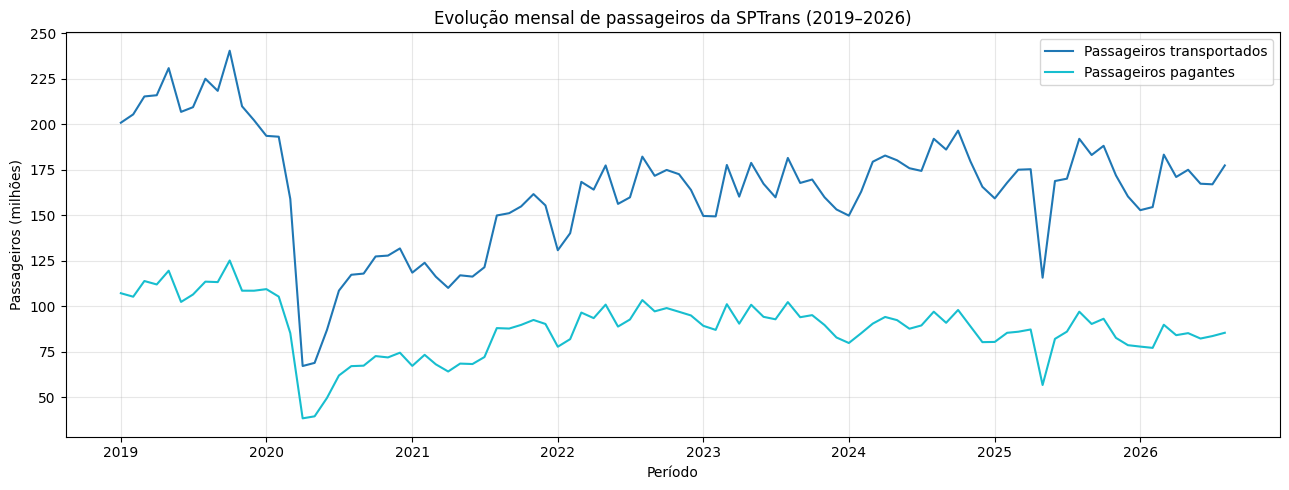

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(13, 5))

plt.plot(
    df_analise["periodo"],
    df_analise["passageiros_transportados"] / 1_000_000,
    label="Passageiros transportados",
    color="#1f77b4"
)

plt.plot(
    df_analise["periodo"],
    df_analise["passageiros_pagantes"] / 1_000_000,
    label="Passageiros pagantes",
    color="#17becf"
)

plt.title(
    "Evolução mensal de passageiros da SPTrans (2019–2026)"
)
plt.xlabel("Período")
plt.ylabel("Passageiros (milhões)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


Observando a evolução entre 2019 e agosto de 2026, podemos destacar:
- 2019: a demanda total apresenta oscilações mensais, com picos próximos de 240 milhões de passageiros.
- 2020: ocorre uma queda muito acentuada, coincidente com o início da pandemia de COVID-19.
- 2021–2022: observamos uma recuperação gradual da demanda.
- 2023–2026: a demanda oscila, mas permanece, em grande parte, abaixo dos níveis registrados em 2019.
Também percebemos que as duas séries seguem trajetórias semelhantes, embora o número de passageiros pagantes seja consideravelmente menor que o total transportado.

#9.Investigar a queda de 2025
Vamos identificar o mês com menor quantidade de passageiros transportados em 2025 e comparar com os meses próximos.

In [ ]:
df_2025 = df_analise[
    df_analise["ano"] == 2025
].copy()

menor_demanda = df_2025.loc[
    df_2025["passageiros_transportados"].idxmin()
]

print("Mês com menor demanda em 2025:")
print(menor_demanda["periodo"].strftime("%m/%Y"))

display(
    df_2025[
        [
            "periodo",
            "passageiros_transportados",
            "passageiros_pagantes",
            "variacao_demanda_pct"
        ]
    ]
)


Mês com menor demanda em 2025:
05/2025


,periodo,passageiros_transportados,passageiros_pagantes,variacao_demanda_pct
72,2025-01-01,159293390,80381624,-3.839850
73,2025-02-01,167910064,85395761,5.409310
74,2025-03-01,175056818,85990465,4.256299
75,2025-04-01,175320293,87220602,0.150508
76,2025-05-01,115692427,56696068,-34.010818
77,2025-06-01,168836200,82061946,45.935395
78,2025-07-01,170118684,86045240,0.759603
79,2025-08-01,192043839,96997470,12.888152
80,2025-09-01,183144150,90258129,-4.634197
81,2025-10-01,188197684,93114607,2.759320


Maio de 2025 apresentou uma queda de 34,01% na demanda, seguida de um crescimento de 45,94% em junho. A queda ocorreu tanto entre passageiros pagantes quanto entre transportados. Isso sugere uma alteração que afetou as duas séries, mas ainda não sabemos se foi um evento real ou uma questão de cobertura dos dados.

Não vamos excluir maio nem substituir os valores por médias. Primeiro precisamos conferir a planilha original.

#10.Verificar a quantidade de linhas de ônibus
Vamos comparar a quantidade de linhas registradas em abril, maio e junho de 2025.

Se maio apresentar muito menos linhas que os outros meses, teremos um indício de possível incompletude na base.

In [ ]:
df_verificacao = df_consolidado[
    (df_consolidado["ano"] == 2025)
    & (df_consolidado["mes"].isin([4, 5, 6]))
].copy()

resumo = df_verificacao.groupby(
    ["ano", "mes"]
).agg(
    quantidade_linhas=("linha", "nunique"),
    passageiros_pagantes=("passageiros_pagantes", "sum"),
    passageiros_transportados=("passageiros_transportados", "sum")
).reset_index()

display(resumo)


,ano,mes,quantidade_linhas,passageiros_pagantes,passageiros_transportados
0,2025,4,1371,87220602,175320293
1,2025,5,1372,56696068,115692427
2,2025,6,1376,82061946,168836200


##10.1 Verificar a cobertura dos dias em maio de 2025
Vamos voltar à planilha original da SPTrans e verificar se ela contém registros para todos os dias do mês.

Como já criamos a função ler_planilha(), podemos reutilizá-la sem reescrever o processo de leitura.


In [ ]:
arquivo_maio = arquivos_validos[
    (arquivos_validos["ano"] == 2025)
    & (arquivos_validos["mes"] == 5)
]["arquivo"].iloc[0]

print("Arquivo:", arquivo_maio)

df_maio, aba, cabecalho = ler_planilha(arquivo_maio)

print("Aba:", aba)
print("Quantidade de registros:", len(df_maio))

df_maio = padronizar_colunas(df_maio)

print("\nColunas disponíveis:")
print(df_maio.columns.tolist())


Arquivo: Consolidado 01-Maio-2025.xls
Aba: SUMARIZAÇÃO do Historico das Ca
Quantidade de registros: 1402

Colunas disponíveis:
['grupo', 'lote', 'empresa', 'linha', 'passageiros pagtes em dinheiro', 'passageiros comum e vt', 'passageiros pgts bu comum m', 'passageiros pagtes estudante', 'passageiros pgts bu est mensal', 'passageiros pgts bu vt mensal', 'passageiros pagantes', 'passageiros int ¿nibus->¿nibus', 'passageiros com gratuidade', 'passageiros com gratuidade est', 'tot passageiros transportados']


Resultado da investigação
O arquivo Consolidado 01-Maio-2025.xls possui:
- 1.402 registros brutos.
- 1.372 linhas de ônibus distintas na base consolidada.
- 15 colunas, incluindo passageiros pagantes, gratuidades e total transportado.
- Nenhuma coluna de data na aba analisada.

##10.2 Verificar outras abas do arquivo
Antes de alterar qualquer dado, vamos descobrir se o Excel possui outras abas com informações sobre o período de referência.

In [ ]:

import os
import pandas as pd

caminho_maio = os.path.join(pasta, arquivo_maio)

excel_maio = pd.ExcelFile(caminho_maio)

print("Abas encontradas:")

for numero, nome in enumerate(excel_maio.sheet_names, start=1):
    print(numero, "-", nome)


Abas encontradas:
1 - SUMARIZAÇÃO do Historico das Ca


Isso confirma que não há outra aba disponível para verificarmos os registros diários. Mas ainda existe uma hipótese importante: o relatório pode ter sido gerado com um intervalo de datas incompleto.

##10.3 Verificar o cabeçalho original da planilha
Vamos conferir as primeiras linhas do arquivo, antes do cabeçalho que o Pandas identificou. Às vezes, o período do relatório aparece ali.

In [ ]:
df_cabecalho = pd.read_excel(
    caminho_maio,
    sheet_name=0,
    header=None,
    nrows=12
)

pd.set_option("display.max_columns", None)

display(df_cabecalho)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,Operacionais - Relatório de TransparênciaCliqu...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Grupo,Lote,Empresa,Linha,Passageiros Pagtes Em Dinheiro SUM,Passageiros Comum E Vt SUM,Passageiros Pgts Bu Comum M SUM,Passageiros Pagtes Estudante SUM,Passageiros Pgts Bu Est Mensal SUM,Passageiros Pgts Bu Vt Mensal SUM,Passageiros Pagantes SUM,Passageiros Int ¿Nibus->¿Nibus SUM,Passageiros Com Gratuidade SUM,Passageiros Com Gratuidade Est SUM,Tot Passageiros Transportados SUM
3,OUTRO PC,192,192,626A10 - CANTINHO DO CEU/MAR PAULISTA,0,0,0,0,0,0,0,0,35750,0,35750
4,OUTRO PC,901,901,SMATEU - TERM,0,70619,4167,3336,0,0,78122,50591,33244,8128,170085
5,GRUPO ESTRUTURAL,E01,Gato Preto,853810 - VILA IARA/PAISSANDU,584,7167,315,387,0,0,8453,2962,3227,1393,16035
6,GRUPO ESTRUTURAL,E01,Gato Preto,938L10 - TTVN CACHOEIRINHA/LAPA,4985,56663,3032,1564,0,0,66244,50845,31796,4376,153261
7,GRUPO ESTRUTURAL,E01,Gato Preto,830001 - TERM PIRITUBA/TERM LAPA,561,6155,399,388,0,0,7503,6113,3948,955,18519
8,GRUPO ESTRUTURAL,E01,Gato Preto,854221 - BRASILANDIA/TERMINAL LAPA,4292,56599,2419,2954,0,0,66264,31863,42862,8141,149130
9,GRUPO ESTRUTURAL,E01,Gato Preto,854210 - BRASILANDIA/PCA DO CORREIO,0,0,0,0,0,0,0,0,149,0,149


O cabeçalho está na linha 2, como nossa função de leitura identificou.



A planilha contém dados consolidados por linha de ônibus.



Não encontramos datas de início e término do período nas primeiras 12 linhas.



O título começa com Operacionais - Relatório de Transparência...


#11.Comparar as mesmas linhas nos três meses
Se a maioria das linhas apresentar uma redução semelhante em maio, isso pode indicar um problema de cobertura temporal do relatório.

In [ ]:
df_linhas_comparacao = df_consolidado[
    (df_consolidado["ano"] == 2025)
    & (df_consolidado["mes"].isin([4, 5, 6]))
].copy()

df_pivot = df_linhas_comparacao.pivot_table(
    index="linha",
    columns="mes",
    values="passageiros_transportados",
    aggfunc="sum"
)

df_pivot = df_pivot.dropna(subset=[4, 5, 6]).copy()

df_pivot = df_pivot[
    (df_pivot[4] > 0)
    & (df_pivot[6] > 0)
]

df_pivot["media_abril_junho"] = (
    df_pivot[4] + df_pivot[6]
) / 2

df_pivot["razao_maio"] = (
    df_pivot[5] / df_pivot["media_abril_junho"]
)

print("Linhas comparáveis:", len(df_pivot))

print(
    "Mediana da razão maio / média abril-junho:",
    round(df_pivot["razao_maio"].median(), 3)
)

print(
    "Percentual de linhas com maio abaixo de 80% da média:",
    round(
        (df_pivot["razao_maio"] < 0.8).mean() * 100,
        2
    ),
    "%"
)


Linhas comparáveis: 1359
Mediana da razão maio / média abril-junho: 0.67
Percentual de linhas com maio abaixo de 80% da média: 98.75 %


A linha típica transportou em maio aproximadamente 67% do volume médio de abril e junho. Além disso, quase todas as linhas apresentaram redução.

Esse padrão é compatível com um relatório que contenha apenas parte do mês, mas ainda não comprova essa hipótese.

Inclusive, maio possui 31 dias, então a diferença não pode ser explicada simplesmente por ter menos dias no calendário.

#12.Investigar se o relatório corresponde a aproximadamente 21 dias
Uma razão de 0,67 equivale a aproximadamente 21 dias de um mês de 31 dias.

Isso levanta uma hipótese: será que o relatório de maio foi gerado antes do encerramento do mês?

Vamos calcular quantos dias de operação o volume de maio representaria, utilizando como referência a média diária dos meses vizinhos.

In [ ]:
abril = resumo.loc[
    resumo["mes"] == 4,
    "passageiros_transportados"
].iloc[0]

maio = resumo.loc[
    resumo["mes"] == 5,
    "passageiros_transportados"
].iloc[0]

junho = resumo.loc[
    resumo["mes"] == 6,
    "passageiros_transportados"
].iloc[0]

media_diaria = (
    (abril / 30) + (junho / 30)
) / 2

dias_equivalentes = maio / media_diaria

print("Média diária de referência:",
      round(media_diaria, 0))

print("Dias equivalentes em maio:",
      round(dias_equivalentes, 2))

print("Dias do calendário em maio:", 31)


Média diária de referência: 5735942.0
Dias equivalentes em maio: 20.17
Dias do calendário em maio: 31


O volume registrado em maio equivale a aproximadamente 20 dias de demanda, considerando a média diária de abril e junho.

Nossa principal hipótese é que o arquivo de maio de 2025 contenha apenas parte do mês. Porém, ainda não podemos confirmar isso: os 20,17 dias são uma estimativa, não a quantidade real de dias registrados.

##12.1 Verificar se existem outros meses suspeitos
Antes de corrigirmos qualquer coisa, quero verificar se maio de 2025 é um caso isolado ou se outros meses também apresentam quedas atípicas.

In [ ]:
df_anomalias = df_analise[
    (df_analise["ano"] >= 2022)
    & (df_analise["variacao_demanda_pct"] < -25)
].copy()

display(
    df_anomalias[
        [
            "periodo",
            "passageiros_transportados",
            "passageiros_pagantes",
            "variacao_demanda_pct"
        ]
    ].round(2)
)

print("Total de meses suspeitos:", len(df_anomalias))


,periodo,passageiros_transportados,passageiros_pagantes,variacao_demanda_pct
76,2025-05-01,115692427,56696068,-34.01


Total de meses suspeitos: 1


Entre janeiro de 2022 e agosto de 2026, maio de 2025 foi o único mês com queda mensal superior a 25%.

##12.2 Sinalizar a anomalia no dataset
Em vez de excluir ou corrigir maio de 2025, vamos criar uma coluna indicando que esse mês precisa de verificação.

Isso é uma boa prática de qualidade de dados e permitirá manter a rastreabilidade no Power BI.

In [ ]:
df_analise["status_qualidade"] = "Regular"

df_analise.loc[
    (df_analise["ano"] == 2025)
    & (df_analise["mes"] == 5),
    "status_qualidade"
] = "Em investigação"

print(df_analise["status_qualidade"].value_counts())

display(
    df_analise[
        df_analise["status_qualidade"] == "Em investigação"
    ][
        [
            "periodo",
            "passageiros_transportados",
            "variacao_demanda_pct",
            "status_qualidade"
        ]
    ]
)


status_qualidade
Regular            91
Em investigação     1
Name: count, dtype: int64


,periodo,passageiros_transportados,variacao_demanda_pct,status_qualidade
76,2025-05-01,115692427,-34.010818,Em investigação


Nosso dataset agora possui 92 meses, sendo 91 classificados como regulares e 1 em investigação.

O mais importante é que preservamos os valores originais de maio de 2025. Isso garante que não vamos introduzir dados artificiais na análise econômica.

#13.Salvar o dataset com a sinalização de qualidade
Como o Google Colab já reiniciou uma vez, vamos salvar nosso progresso no Google Drive para não precisar reconstruir as variáveis novamente.

In [ ]:
import os

pasta_saida = (
    "/content/drive/MyDrive/Economia_2 2026/Dados_Tratados"
)

os.makedirs(pasta_saida, exist_ok=True)

caminho_analise = os.path.join(
    pasta_saida,
    "sptrans_analise_economica_2019_2026.csv"
)

df_analise.to_csv(
    caminho_analise,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

print("Arquivo salvo com sucesso!")
print("Local:", caminho_analise)
print("Registros:", len(df_analise))
print("Colunas:", df_analise.columns.tolist())


Arquivo salvo com sucesso!
Local: /content/drive/MyDrive/Economia_2 2026/Dados_Tratados/sptrans_analise_economica_2019_2026.csv
Registros: 92
Colunas: ['ano', 'mes', 'passageiros_pagantes', 'passageiros_transportados', 'periodo', 'tarifa_media', 'variacao_demanda_pct', 'variacao_tarifa_pct', 'variacao_interanual_pct', 'variacao_pagantes_interanual_pct', 'participacao_pagantes_pct', 'status_qualidade']


##13.1 Pasta de exportação

In [ ]:

import os
import pandas as pd

pasta_saida = (
    "/content/drive/MyDrive/Economia_2 2026/Dados_Tratados"
)

df_analise = pd.read_csv(
    os.path.join(
        pasta_saida,
        "sptrans_analise_economica_2019_2026.csv"
    )
)

df_mensal = pd.read_csv(
    os.path.join(
        pasta_saida,
        "sptrans_mensal_2019_2026.csv"
    )
)

df_linhas = pd.read_csv(
    os.path.join(
        pasta_saida,
        "sptrans_linhas_2019_2026.csv"
    )
)

caminho_excel = os.path.join(
    pasta_saida,
    "SPTrans_Dados_PowerBI.xlsx"
)

with pd.ExcelWriter(caminho_excel, engine="openpyxl") as writer:

    df_analise.to_excel(
        writer,
        sheet_name="Analise_Economica",
        index=False
    )

    df_mensal.to_excel(
        writer,
        sheet_name="Demanda_Mensal",
        index=False
    )

    df_linhas.to_excel(
        writer,
        sheet_name="Dados_por_Linha",
        index=False
    )

print("Excel exportado com sucesso!")
print("Arquivo:", caminho_excel)
print("Registros da análise:", len(df_analise))
print("Registros por linha:", len(df_linhas))


Excel exportado com sucesso!
Arquivo: /content/drive/MyDrive/Economia_2 2026/Dados_Tratados/SPTrans_Dados_PowerBI.xlsx
Registros da análise: 92
Registros por linha: 124749


#14.Verificação da execução do código
com a finalização do trabalho, fazemos uma atualização de registros.

In [ ]:

import pandas as pd
import os

pasta_saida = "/content/drive/MyDrive/Economia_2 2026/Dados_Tratados"

df_linhas = pd.read_csv(
    os.path.join(pasta_saida, "sptrans_linhas_2019_2026.csv")
)

df_analise = pd.read_csv(
    os.path.join(pasta_saida, "sptrans_analise_economica_2019_2026.csv"),
    parse_dates=["periodo"]
)

print("Registros por linha:", len(df_linhas))
print("Meses analisados:", len(df_analise))

print("Meses duplicados:",
      df_analise.duplicated(["ano", "mes"]).sum())

print("Períodos sem data:",
      df_analise["periodo"].isna().sum())

print("Tarifas ausentes:",
      df_analise["tarifa_media"].isna().sum())

print("Status de qualidade:")
print(df_analise["status_qualidade"].value_counts())


Registros por linha: 124749
Meses analisados: 92
Meses duplicados: 0
Períodos sem data: 0
Tarifas ausentes: 0
Status de qualidade:
status_qualidade
Regular            91
Em investigação     1
Name: count, dtype: int64


Os resultados mostram que a base consolidada está consistente nos critérios que acabamos de testar.

##14.1 Conferir a integridade dos dados
Agora vamos verificar algo essencial para o relatório técnico: se a soma dos passageiros de cada linha de ônibus corresponde aos totais mensais que utilizamos nos indicadores econômicos.

In [ ]:
df_totais = df_linhas.groupby(
    ["ano", "mes"], as_index=False
)[
    ["passageiros_transportados", "passageiros_pagantes"]
].sum()

df_validacao = df_totais.merge(
    df_analise[
        ["ano", "mes",
         "passageiros_transportados",
         "passageiros_pagantes"]
    ],
    on=["ano", "mes"],
    how="outer",
    suffixes=("_linhas", "_analise"),
    indicator=True
)

for coluna in [
    "passageiros_transportados",
    "passageiros_pagantes"
]:
    df_validacao[f"diferenca_{coluna}"] = (
        df_validacao[f"{coluna}_linhas"]
        - df_validacao[f"{coluna}_analise"]
    )

print("Meses comparados:", len(df_validacao))

print("Meses sem correspondência:",
      (df_validacao["_merge"] != "both").sum())

print("Divergências em passageiros transportados:",
      (df_validacao["diferenca_passageiros_transportados"]
       .fillna(0) != 0).sum())

print("Divergências em passageiros pagantes:",
      (df_validacao["diferenca_passageiros_pagantes"]
       .fillna(0) != 0).sum())

display(df_validacao.tail())


Meses comparados: 92
Meses sem correspondência: 0
Divergências em passageiros transportados: 0
Divergências em passageiros pagantes: 0


,ano,mes,passageiros_transportados_linhas,passageiros_pagantes_linhas,passageiros_transportados_analise,passageiros_pagantes_analise,_merge,diferenca_passageiros_transportados,diferenca_passageiros_pagantes
87,2026,4,171059490,84090951,171059490,84090951,both,0,0
88,2026,5,175017065,85213332,175017065,85213332,both,0,0
89,2026,6,167354184,82246054,167354184,82246054,both,0,0
90,2026,7,167032455,83601914,167032455,83601914,both,0,0
91,2026,8,177406013,85412843,177406013,85412843,both,0,0


nossa consolidação passou na validação de integridade.

#15.Validar os indicadores econômicos
Agora precisamos conferir se os cálculos realizados no Python estão matematicamente corretos, especialmente:
- Variação mensal da demanda.
- Variação mensal da tarifa.
- Variação interanual da demanda.
- Participação percentual dos passageiros pagantes.

In [ ]:
import numpy as np

df_teste = df_analise.sort_values("periodo").copy()

calculos = {
    "variacao_demanda_pct":
        df_teste["passageiros_transportados"].pct_change() * 100,

    "variacao_tarifa_pct":
        df_teste["tarifa_media"].pct_change() * 100,

    "variacao_interanual_pct":
        df_teste["passageiros_transportados"].pct_change(12) * 100,

    "variacao_pagantes_interanual_pct":
        df_teste["passageiros_pagantes"].pct_change(12) * 100,

    "participacao_pagantes_pct":
        df_teste["passageiros_pagantes"]
        / df_teste["passageiros_transportados"] * 100
}

for coluna, calculado in calculos.items():

    original = df_teste[coluna]

    divergencias = ~np.isclose(
        original,
        calculado,
        rtol=1e-9,
        atol=1e-8,
        equal_nan=True
    )

    print(coluna, ":", divergencias.sum(), "divergências")


variacao_demanda_pct : 0 divergências
variacao_tarifa_pct : 0 divergências
variacao_interanual_pct : 0 divergências
variacao_pagantes_interanual_pct : 0 divergências
participacao_pagantes_pct : 0 divergências


Todos os cinco indicadores econômicos passaram na validação.

##15.1 Conferir as tarifas de ônibus
Antes de finalizar a programação, precisamos verificar os valores utilizados no projeto. Vamos primeiro verificar se a tarifa média mensal do dataset corresponde a essas datas e valores

In [ ]:
df_tarifas_verificacao = df_analise[
    ["ano", "mes", "tarifa_media"]
].copy()

df_tarifas_verificacao = df_tarifas_verificacao[
    df_tarifas_verificacao["mes"].isin([1, 2])
]

display(
    df_tarifas_verificacao.sort_values(
        ["ano", "mes"]
    ).round(4)
)

print(
    "Tarifas médias distintas:",
    df_analise["tarifa_media"].nunique()
)


,ano,mes,tarifa_media
0,2019,1,4.2419
1,2019,2,4.3000
12,2020,1,4.4000
13,2020,2,4.4000
24,2021,1,4.4000
25,2021,2,4.4000
36,2022,1,4.4000
37,2022,2,4.4000
48,2023,1,4.4000
49,2023,2,4.4000


Tarifas médias distintas: 7


a coluna tarifa_media está preenchida e apresenta o comportamento esperado para os reajustes que cadastramos.

#16.Investigação da anomalia de maio de 2025
Vamos comparar abril, maio e junho de 2025 para quantificar a diferença entre os três meses.

In [ ]:
df_comparacao = df_analise[
    (df_analise["ano"] == 2025)
    & (df_analise["mes"].isin([4, 5, 6]))
].copy()

df_comparacao = df_comparacao.sort_values("mes")

abril = df_comparacao.loc[
    df_comparacao["mes"] == 4,
    "passageiros_transportados"
].iloc[0]

maio = df_comparacao.loc[
    df_comparacao["mes"] == 5,
    "passageiros_transportados"
].iloc[0]

junho = df_comparacao.loc[
    df_comparacao["mes"] == 6,
    "passageiros_transportados"
].iloc[0]

media_vizinhos = (abril + junho) / 2

diferenca_pct = (
    (maio / media_vizinhos) - 1
) * 100

print("Abril:", f"{abril:,.0f}")
print("Maio:", f"{maio:,.0f}")
print("Junho:", f"{junho:,.0f}")

print(
    "Média de abril e junho:",
    f"{media_vizinhos:,.0f}"
)

print(
    "Diferença de maio em relação à média:",
    f"{diferenca_pct:.2f}%"
)

display(
    df_comparacao[
        ["periodo", "passageiros_transportados",
         "variacao_demanda_pct", "status_qualidade"]
    ]
)


Abril: 175,320,293
Maio: 115,692,427
Junho: 168,836,200
Média de abril e junho: 172,078,246
Diferença de maio em relação à média: -32.77%


,periodo,passageiros_transportados,variacao_demanda_pct,status_qualidade
75,2025-04-01,175320293,0.150508,Regular
76,2025-05-01,115692427,-34.010818,Em investigação
77,2025-06-01,168836200,45.935395,Regular


Em maio, foram registrados aproximadamente 56,4 milhões de passageiros a menos do que a média de abril e junho.

A sequência chama atenção:
- Abril → maio: queda de 34,01%.
- Maio → junho: crescimento de 45,94%.
- Maio em relação à média dos meses vizinhos: 32,77% abaixo.

##16.1 Comparar maio de 2025 com maio de outros anos
Antes de tomar uma decisão, vamos verificar se a queda também aparece quando comparamos o mesmo mês em anos diferentes.

Essa comparação é importante porque o transporte coletivo apresenta sazonalidade: comparar maio com outros meses de maio reduz parte desse efeito.

In [ ]:
df_maios = df_analise[
    df_analise["mes"] == 5
].copy()
df_maios = df_maios.sort_values("ano")

df_maios["variacao_maio_pct"] = (
    df_maios["passageiros_transportados"]
    .pct_change() * 100
)

display(
    df_maios[
        [
            "ano",
            "passageiros_transportados",
            "variacao_maio_pct",
            "status_qualidade"
        ]
    ].round(2)
)


,ano,passageiros_transportados,variacao_maio_pct,status_qualidade
4,2019,230893959,NaN,Regular
16,2020,68856949,-70.18,Regular
28,2021,117006538,69.93,Regular
40,2022,177406036,51.62,Regular
52,2023,178805944,0.79,Regular
64,2024,180225416,0.79,Regular
76,2025,115692427,-35.81,Em investigação
88,2026,175017065,51.28,Regular


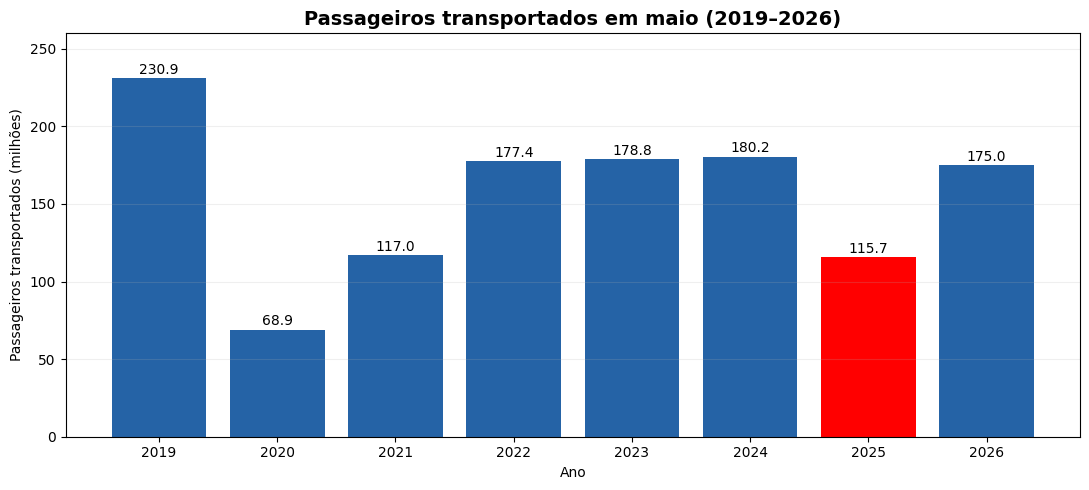

In [ ]:
import matplotlib.pyplot as plt

df_maios = df_analise[
    df_analise["mes"] == 5
].sort_values("ano").copy()

df_maios["passageiros_milhoes"] = (
    df_maios["passageiros_transportados"] / 1_000_000
)

cores = [
    "red" if ano == 2025 else "#2563A6"
    for ano in df_maios["ano"]
]

plt.figure(figsize=(11, 5))

barras = plt.bar(
    df_maios["ano"].astype(str),
    df_maios["passageiros_milhoes"],
    color=cores
)

for barra in barras:
    altura = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 3,
        f"{altura:.1f}",
        ha="center",
        fontsize=10
    )

plt.title(
    "Passageiros transportados em maio (2019–2026)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Ano")
plt.ylabel("Passageiros transportados (milhões)")
plt.ylim(0, 260)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/Economia_2 2026/Dados_Tratados/"
    "grafico_maio_2019_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


##16.2 Investigação de anomalia: Maio de 2025

Durante a etapa de validação e controle de qualidade, foi identificada uma redução atípica no número de passageiros transportados pela SPTrans em maio de 2025.

O período apresentou 115.692.427 passageiros transportados, representando uma queda de 34,01% em relação a abril de 2025 e de 35,81% em comparação com maio de 2024.

A análise dos meses vizinhos demonstrou que o volume registrado em maio ficou 32,77% abaixo da média de abril e junho de 2025. Além disso, observou-se uma recuperação de 45,94% no mês seguinte.

A comparação histórica dos meses de maio entre 2019 e 2026 também evidenciou que o valor de 2025 ficou abaixo dos patamares observados entre 2022 e 2024 e em 2026.

Esses resultados indicam um comportamento estatisticamente atípico, mas não permitem determinar sua causa. Entre as hipóteses consideradas está uma possível diferença na cobertura temporal do relatório original, ainda não confirmada documentalmente.

Por esse motivo, optou-se pela preservação dos dados originais e pela classificação do registro como **"Em investigação"**, sem exclusão ou imputação de valores.

Essa decisão mantém a rastreabilidade do processamento e permite que análises posteriores considerem explicitamente a limitação identificada.

#17.Validação das tarifas do transporte coletivo

Os valores históricos das tarifas básicas de ônibus do município de São Paulo foram conferidos com os registros oficiais da SPTrans e da Prefeitura Municipal de São Paulo.

Foram identificados os reajustes de 2019, 2020, 2025 e 2026, considerando suas respectivas datas de vigência. Para os meses em que ocorreram alterações tarifárias, calculou-se uma média ponderada pela quantidade de dias de vigência de cada valor.

A variável `tarifa_media` representa, portanto, uma aproximação mensal da tarifa básica nominal, não correspondendo necessariamente ao valor médio efetivamente pago pelos usuários.

**Fontes:**
- SPTrans — https://www.sptrans.com.br/tarifas
- Prefeitura de São Paulo — https://prefeitura.sp.gov.br/web/mobilidade/w/institucional/sptrans/acesso_a_informacao/150849